#Install Library

In [ ]:
# Instalasi library (jika belum terinstal)
!pip install pandas matplotlib seaborn numpy plotly statsmodels

# Mengimpor library yang dibutuhkan
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly.express as px
import os
from google.colab import drive
import statsmodels.api as sm
import statsmodels.tsa.seasonal as seasonal
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import math
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.holtwinters import Holt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

#Import Dataset

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
folder_path = '/content/drive/MyDrive/Dataset Crypto'
file_btc = os.path.join(folder_path, 'Bitcoin.csv')
btc_data = pd.read_csv(file_btc)
btc_data['snapped_at'] = pd.to_datetime(btc_data['snapped_at'], format='%Y-%m-%d %H:%M:%S UTC')
print("BTC Data:")
btc_data

BTC Data:


,snapped_at,price,market_cap,total_volume
0,2013-04-28,135.300000,1.500518e+09,0.000000e+00
1,2013-04-29,141.960000,1.575032e+09,0.000000e+00
2,2013-04-30,135.300000,1.501657e+09,0.000000e+00
3,2013-05-01,117.000000,1.298952e+09,0.000000e+00
4,2013-05-02,103.430000,1.148668e+09,0.000000e+00
...,...,...,...,...
4603,2025-12-06,89307.091545,1.782799e+12,5.019314e+10
4604,2025-12-07,89244.762081,1.781195e+12,2.481868e+10
4605,2025-12-08,90162.907140,1.799657e+12,3.391289e+10
4606,2025-12-09,90618.053520,1.808395e+12,4.546649e+10


In [ ]:
file_ethereum = os.path.join(folder_path, 'Ethereum.csv')
eth_data = pd.read_csv(file_ethereum)
eth_data['snapped_at'] = pd.to_datetime(eth_data['snapped_at'], format='%Y-%m-%d %H:%M:%S UTC')
print("Ethereum Data:")
eth_data.head()

Ethereum Data:


,snapped_at,price,market_cap,total_volume
0,2015-08-07,2.831620,0.000000e+00,9.062200e+04
1,2015-08-08,1.330750,8.033948e+07,3.680700e+05
2,2015-08-10,0.687586,4.155631e+07,4.004641e+05
3,2015-08-11,1.067379,6.453901e+07,1.518998e+06
4,2015-08-12,1.256613,7.601326e+07,2.073893e+06


In [ ]:
file_solana = os.path.join(folder_path,'Solana.csv')
solana_data = pd.read_csv(file_solana)
solana_data['snapped_at'] = pd.to_datetime(solana_data['snapped_at'], format='%Y-%m-%d %H:%M:%S UTC')
print("Solana Data:")
solana_data.head()

Solana Data:


,snapped_at,price,market_cap,total_volume
0,2020-04-11,0.957606,7.827652e+06,9.267267e+07
1,2020-04-12,0.784711,6.173608e+06,4.945869e+07
2,2020-04-13,0.875994,7.269680e+06,3.782101e+07
3,2020-04-14,0.786712,6.302364e+06,1.957921e+07
4,2020-04-15,0.666673,5.306221e+06,1.752353e+07


# Preprocessing BTC, ETH dan SOL

In [ ]:
# Fungsi untuk memeriksa missing data dan jenis data untuk berbagai dataset
def check_data(dataset, name="Dataset"):
    # Memeriksa apakah ada data yang hilang pada setiap kolom
    missing_data = dataset.isnull().sum()

    # Memeriksa jenis data pada setiap kolom
    data_types = dataset.dtypes

    # Menampilkan hasil
    print(f"Jumlah data yang hilang per kolom pada {name}:")
    print(missing_data)

    print(f"\nJenis data per kolom pada {name}:")
    print(data_types)

# Menggunakan fungsi untuk Solana, Ethereum, dan Bitcoin
check_data(solana_data, name="Solana Data")
check_data(eth_data, name="Ethereum Data")
check_data(btc_data, name="Bitcoin Data")

# Pastikan kolom data menjadi 1 jika ada missing values
solana_data_clean = solana_data.fillna(1)
eth_data_clean = eth_data.fillna(1)
btc_data_clean = btc_data.fillna(1)

# Tampilkan data yang sudah dibersihkan
print("\nData Solana setelah penggantian missing values dengan 1:")
print(solana_data_clean)

print("\nData Ethereum setelah penggantian missing values dengan 1:")
print(eth_data_clean)

print("\nData Bitcoin setelah penggantian missing values dengan 1:")
print(btc_data_clean)

Jumlah data yang hilang per kolom pada Solana Data:
snapped_at      0
price           0
market_cap      0
total_volume    0
dtype: int64

Jenis data per kolom pada Solana Data:
snapped_at      datetime64[ns]
price                  float64
market_cap             float64
total_volume           float64
dtype: object
Jumlah data yang hilang per kolom pada Ethereum Data:
snapped_at      0
price           0
market_cap      0
total_volume    0
dtype: int64

Jenis data per kolom pada Ethereum Data:
snapped_at      datetime64[ns]
price                  float64
market_cap             float64
total_volume           float64
dtype: object
Jumlah data yang hilang per kolom pada Bitcoin Data:
snapped_at      0
price           0
market_cap      0
total_volume    0
dtype: int64

Jenis data per kolom pada Bitcoin Data:
snapped_at      datetime64[ns]
price                  float64
market_cap             float64
total_volume           float64
dtype: object

Data Solana setelah penggantian missing values d

In [ ]:
# Kolom yang akan di-drop
columns_to_drop = ['market_cap', 'total_volume']

# Drop kolom yang sama dari ketiga dataset
solana_clean = solana_data.drop(columns=columns_to_drop)
eth_clean = eth_data.drop(columns=columns_to_drop)
btc_clean = btc_data.drop(columns=columns_to_drop)

# Menampilkan hasil untuk memastikan kolom telah dihapus
print("Solana Data setelah drop kolom:")
print(solana_clean.head())

print("\nEthereum Data setelah drop kolom:")
print(eth_clean.head())

print("\nBitcoin Data setelah drop kolom:")
print(btc_clean.head())

Solana Data setelah drop kolom:
  snapped_at     price
0 2020-04-11  0.957606
1 2020-04-12  0.784711
2 2020-04-13  0.875994
3 2020-04-14  0.786712
4 2020-04-15  0.666673

Ethereum Data setelah drop kolom:
  snapped_at     price
0 2015-08-07  2.831620
1 2015-08-08  1.330750
2 2015-08-10  0.687586
3 2015-08-11  1.067379
4 2015-08-12  1.256613

Bitcoin Data setelah drop kolom:
  snapped_at   price
0 2013-04-28  135.30
1 2013-04-29  141.96
2 2013-04-30  135.30
3 2013-05-01  117.00
4 2013-05-02  103.43


#Exploratory Data Analysis (EDA)

Price BTC

In [ ]:
fig = px.line(btc_clean, x='snapped_at', y='price', title="Harga Bitcoin")
fig.update_layout(plot_bgcolor='rgba(0, 0, 0, 0)')
fig.update_traces(line=dict(color="rgb(255, 140, 0)"))
fig.update_layout(width=800, height=400)
fig.update_layout(
    xaxis_title="Tahun",
    yaxis_title="Harga"
)
fig.show()

Decomposition

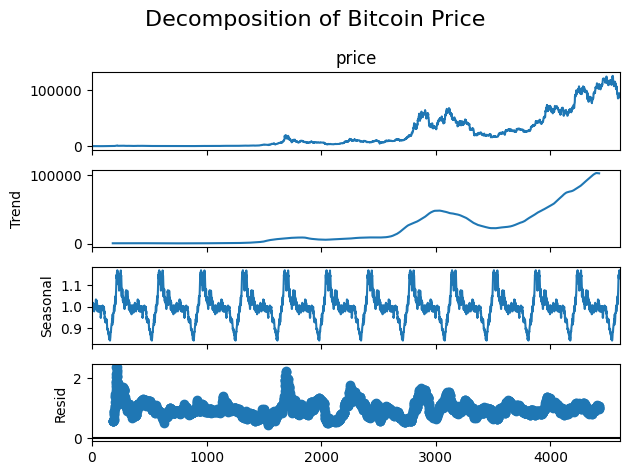

In [ ]:
result = seasonal_decompose(btc_clean['price'], model='multiplicative', period=365)
result.plot()
plt.suptitle('Decomposition of Bitcoin Price', fontsize=16)
plt.tight_layout()
plt.show()

Matrix Correltion

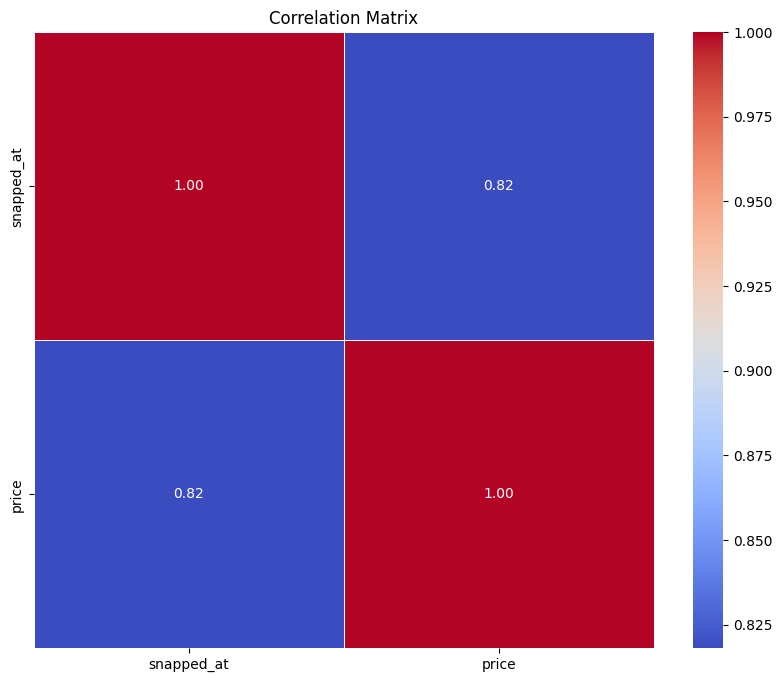

In [ ]:
correlation_matrix = btc_clean.corr()

# Menampilkan matriks korelasi dengan heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

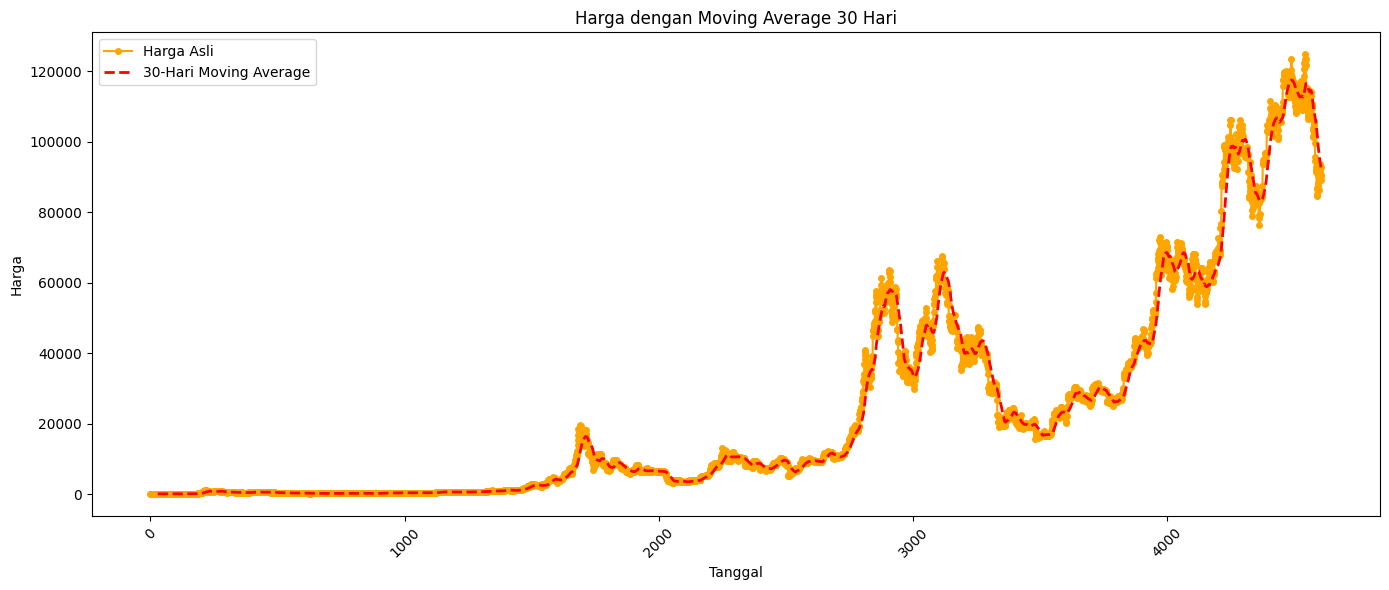

In [ ]:
btc_clean['rolling_mean'] = btc_clean['price'].rolling(window=30).mean()
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(btc_clean.index, btc_clean['price'], label='Harga Asli', color='orange', linewidth=1.5, marker='o', markersize=4)
ax.plot(btc_clean.index, btc_clean['rolling_mean'], label='30-Hari Moving Average', color='red', linewidth=2, linestyle='--')

ax.set_title('Harga dengan Moving Average 30 Hari')
ax.set_xlabel('Tanggal')
ax.set_ylabel('Harga')
ax.legend()
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# Uji Kelayakan Metode

In [ ]:
# Fungsi adf_test untuk melakukan Augmented Dickey-Fuller test
def adf_test(series, title=''):
    """Perform Augmented Dickey-Fuller test"""
    result = adfuller(series.dropna(), autolag='AIC')  # Menghilangkan nilai NaN sebelum diuji

    print(f'ADF Test Results - {title}')
    print('='*50)
    print(f'ADF Statistic: {result[0]:.4f}')
    print(f'p-value: {result[1]:.4f}')
    print(f'Lags Used: {result[2]}')
    print(f'Number of Observations: {result[3]}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'   {key}: {value:.4f}')

    if result[1] <= 0.05:
        print('\n✅ Conclusion: Series is STATIONARY (reject H0)')
    else:
        print('\n⚠️ Conclusion: Series is NON-STATIONARY (fail to reject H0)')
    print()


In [ ]:
# Differencing jika non-stationary
ts_diff = btc_clean.diff().dropna()
adf_test(ts_diff['price'], 'Weekly price (1st Difference)')

ADF Test Results - Weekly price (1st Difference)
ADF Statistic: -10.1941
p-value: 0.0000
Lags Used: 30
Number of Observations: 4547
Critical Values:
   1%: -3.4318
   5%: -2.8622
   10%: -2.5671

✅ Conclusion: Series is STATIONARY (reject H0)



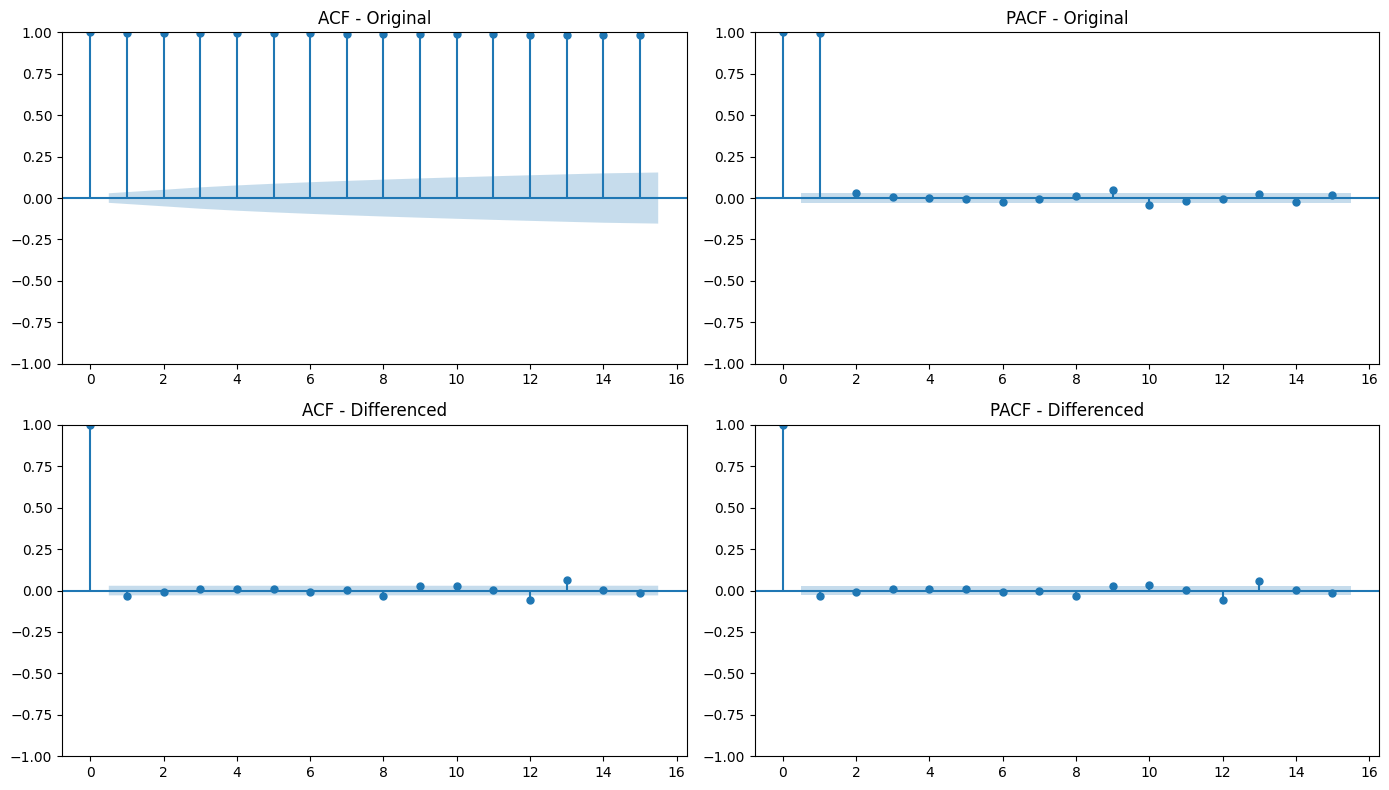

In [ ]:
# ACF dan PACF plots
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Original series
plot_acf(btc_clean['price'], lags=15, ax=axes[0, 0], title='ACF - Original')
plot_pacf(btc_clean['price'], lags=15, ax=axes[0, 1], title='PACF - Original')

# Differenced series
plot_acf(ts_diff['price'], lags=15, ax=axes[1, 0], title='ACF - Differenced')
plot_pacf(ts_diff['price'], lags=15, ax=axes[1, 1], title='PACF - Differenced')

plt.tight_layout()
plt.show()

In [ ]:
# Split data: 80% train, 20% test
train_size = int(len(btc_clean )* 0.8)
train = btc_clean[:train_size]
test = btc_clean[train_size:]

print(f"Train size: {len(train)} weeks ({train.index.min()} to {train.index.max()})")
print(f"Test size: {len(test)} weeks ({test.index.min()} to {test.index.max()})")

Train size: 3686 weeks (0 to 3685)
Test size: 922 weeks (3686 to 4607)


In [ ]:
# Helper function untuk evaluasi
def evaluate_forecast(actual, predicted, model_name):
    """Calculate and display forecast metrics"""
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(actual, predicted) * 100

    print(f"\n{model_name} - Evaluation Metrics:")
    print(f"  MAE:  ${mae:,.2f}")
    print(f"  RMSE: ${rmse:,.2f}")
    print(f"  MAPE: {mape:.2f}%")

    return {'Model': model_name, 'MAE': mae, 'RMSE': rmse, 'MAPE': mape}

# Store results
results = []

In [ ]:
# Naive: Use last observed value as forecast
naive_forecast_value = train['price'].iloc[-1]
naive_forecast = pd.Series([naive_forecast_value] * len(test), index=test.index)

results.append(evaluate_forecast(test['price'], naive_forecast, 'Naive (Baseline)'))


Naive (Baseline) - Evaluation Metrics:
  MAE:  $44,872.24
  RMSE: $53,727.12
  MAPE: 53.33%


In [ ]:
# Menentukan window untuk Moving Average
window = 4

ma_value = btc_clean['price'].iloc[-window:].mean()
sma_forecast = pd.Series([ma_value] * len(test), index=test.index)
results.append(evaluate_forecast(test['price'], sma_forecast, f'Simple MA (window={window})'))


Simple MA (window=4) - Evaluation Metrics:
  MAE:  $29,344.60
  RMSE: $35,266.77
  MAPE: 68.14%


In [ ]:
# Simple Exponential Smoothing

ses_model = SimpleExpSmoothing(train['price']).fit(smoothing_level=0.3, optimized=False)
ses_forecast = ses_model.forecast(len(test))
ses_forecast.index = test.index

results.append(evaluate_forecast(test['price'], ses_forecast, 'Simple Exp Smoothing'))


Simple Exp Smoothing - Evaluation Metrics:
  MAE:  $44,525.90
  RMSE: $53,396.77
  MAPE: 52.83%


In [ ]:
# Holt's Linear Trend Method

holt_model = Holt(train['price']).fit(smoothing_level=0.3, smoothing_trend=0.1)
holt_forecast = holt_model.forecast(len(test))
holt_forecast.index = test.index

results.append(evaluate_forecast(test['price'], holt_forecast, "Holt's Linear Trend"))


Holt's Linear Trend - Evaluation Metrics:
  MAE:  $41,048.55
  RMSE: $49,348.93
  MAPE: 48.64%


/usr/local/lib/python3.12/dist-packages/pandas/util/_decorators.py:213: EstimationWarning:

Model has no free parameters to estimate. Set optimized=False to suppress this warning



In [ ]:
# Pisahkan data training dan testing
train = btc_clean['price'][:len(btc_clean) - len(test)]  # Ambil data training
test = btc_clean['price'][len(btc_clean) - len(test):]  # Ambil data testing

try:
    # Holt-Winters model (Additive) dengan seasonal period = 4 (untuk pola bulanan)
    hw_model = ExponentialSmoothing(
        train,
        trend='add',
        seasonal='add',
        seasonal_periods=4
    ).fit()

    # Ramalan untuk data test
    hw_forecast = hw_model.forecast(len(test))

    # Sesuaikan index hasil ramalan agar sesuai dengan data test
    hw_forecast.index = test.index

    # Evaluasi hasil ramalan
    results.append(evaluate_forecast(test, hw_forecast, 'Holt-Winters (Additive)'))
except Exception as e:
    print(f"Holt-Winters failed: {e}")
    hw_forecast = None


Holt-Winters (Additive) - Evaluation Metrics:
  MAE:  $41,193.62
  RMSE: $49,459.73
  MAPE: 48.87%


In [ ]:
# ARIMA dengan parameter manual berdasarkan ACF/PACF
# p=1, d=1, q=1 sebagai starting point
from statsmodels.tsa.arima.model import ARIMA


arima_model = ARIMA(train, order=(1, 1, 1)).fit()
print(arima_model.summary())

                               SARIMAX Results                                
Dep. Variable:                  price   No. Observations:                 3686
Model:                 ARIMA(1, 1, 1)   Log Likelihood              -29546.591
Date:                Wed, 17 Dec 2025   AIC                          59099.183
Time:                        18:00:34   BIC                          59117.819
Sample:                             0   HQIC                         59105.816
                               - 3686                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0563      0.329     -0.171      0.864      -0.701       0.588
ma.L1          0.0335      0.329      0.102      0.919      -0.612       0.679
sigma2        5.4e+05   3832.914    140.888      0.0

In [ ]:
# ARIMA forecast
arima_forecast = arima_model.forecast(steps=len(test))
arima_forecast.index = test.index

results.append(evaluate_forecast(test, arima_forecast, 'ARIMA(1,1,1)'))


ARIMA(1,1,1) - Evaluation Metrics:
  MAE:  $44,864.48
  RMSE: $53,719.81
  MAPE: 53.32%


In [ ]:
# Try different ARIMA parameters
best_aic = float('inf')
best_order = None
best_model = None

print("Searching for best ARIMA parameters...")
for p in range(0, 3):
    for d in range(0, 2):
        for q in range(0, 3):
            try:
                model = ARIMA(train, order=(p, d, q)).fit()
                if model.aic < best_aic:
                    best_aic = model.aic
                    best_order = (p, d, q)
                    best_model = model
            except:
                continue

print(f"\nBest ARIMA order: {best_order}")
print(f"Best AIC: {best_aic:.2f}")

Searching for best ARIMA parameters...


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning:

Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning:

Non-invertible starting MA parameters found. Using zeros as starting parameters.




Best ARIMA order: (2, 1, 2)
Best AIC: 59076.80


In [ ]:
# Forecast dengan best ARIMA
best_arima_forecast = best_model.forecast(steps=len(test))
best_arima_forecast.index = test.index

results.append(evaluate_forecast(test, best_arima_forecast, f'ARIMA{best_order} (Best)'))


ARIMA(2, 1, 2) (Best) - Evaluation Metrics:
  MAE:  $44,878.03
  RMSE: $53,732.56
  MAPE: 53.34%


Prophet(Opsional)

In [ ]:
# Prophet requires specific format
try:
    from prophet import Prophet

    # Prepare data for Prophet
    prophet_train = pd.DataFrame({
        'ds': btc_clean['snapped_at'].iloc[:len(train)], # Use 'snapped_at' for dates
        'y': train.values
    })

    # Fit model
    prophet_model = Prophet(yearly_seasonality=False, weekly_seasonality=False,
                           daily_seasonality=False)
    prophet_model.fit(prophet_train)

    # Create future dataframe
    future = pd.DataFrame({'ds': btc_clean['snapped_at'].iloc[len(train):]}) # Use 'snapped_at' for future dates
    prophet_forecast_df = prophet_model.predict(future)
    prophet_forecast = pd.Series(prophet_forecast_df['yhat'].values, index=test.index)

    results.append(evaluate_forecast(test, prophet_forecast, 'Prophet')) # Pass 'price' column for evaluation
    prophet_available = True

except ImportError:
    print("Prophet not installed. Skipping Prophet model.")
    print("Install with: pip install prophet")
    prophet_forecast = None
    prophet_available = False


Prophet - Evaluation Metrics:
  MAE:  $76,374.31
  RMSE: $86,915.59
  MAPE: 98.19%


Model Comparison & Visualization

In [ ]:
# Results comparison table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('MAPE')
print("\n" + "="*60)
print("MODEL COMPARISON - Sorted by MAPE (Best to Worst)")
print("="*60)
print(results_df.to_string(index=False))
print("="*60)


MODEL COMPARISON - Sorted by MAPE (Best to Worst)
                  Model          MAE         RMSE      MAPE
    Holt's Linear Trend 41048.548413 49348.931797 48.638876
Holt-Winters (Additive) 41193.617329 49459.731996 48.867562
   Simple Exp Smoothing 44525.898612 53396.770242 52.831966
           ARIMA(1,1,1) 44864.477424 53719.807321 53.322795
       Naive (Baseline) 44872.236005 53727.115468 53.334290
  ARIMA(2, 1, 2) (Best) 44878.029730 53732.564702 53.342892
   Simple MA (window=4) 29344.597367 35266.769406 68.137993
                Prophet 76374.312348 86915.590066 98.193984


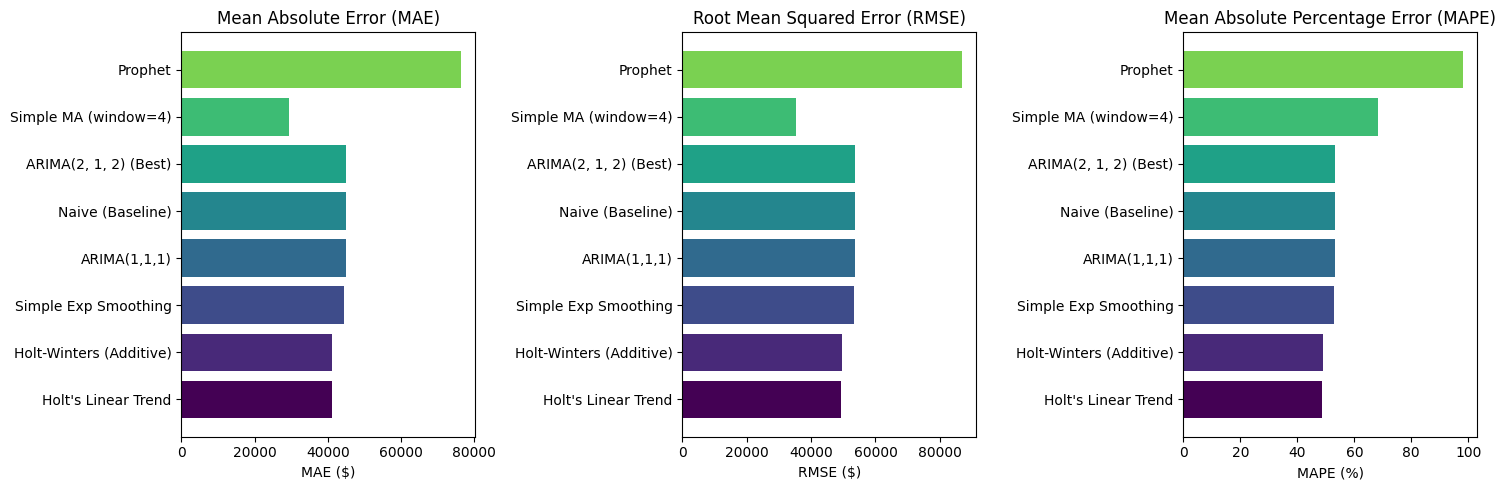

In [ ]:
# Bar chart comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

colors = plt.cm.viridis(np.linspace(0, 0.8, len(results_df)))

# MAE comparison
axes[0].barh(results_df['Model'], results_df['MAE'], color=colors)
axes[0].set_title('Mean Absolute Error (MAE)')
axes[0].set_xlabel('MAE ($)')

# RMSE comparison
axes[1].barh(results_df['Model'], results_df['RMSE'], color=colors)
axes[1].set_title('Root Mean Squared Error (RMSE)')
axes[1].set_xlabel('RMSE ($)')

# MAPE comparison
axes[2].barh(results_df['Model'], results_df['MAPE'], color=colors)
axes[2].set_title('Mean Absolute Percentage Error (MAPE)')
axes[2].set_xlabel('MAPE (%)')

plt.tight_layout()
plt.show()

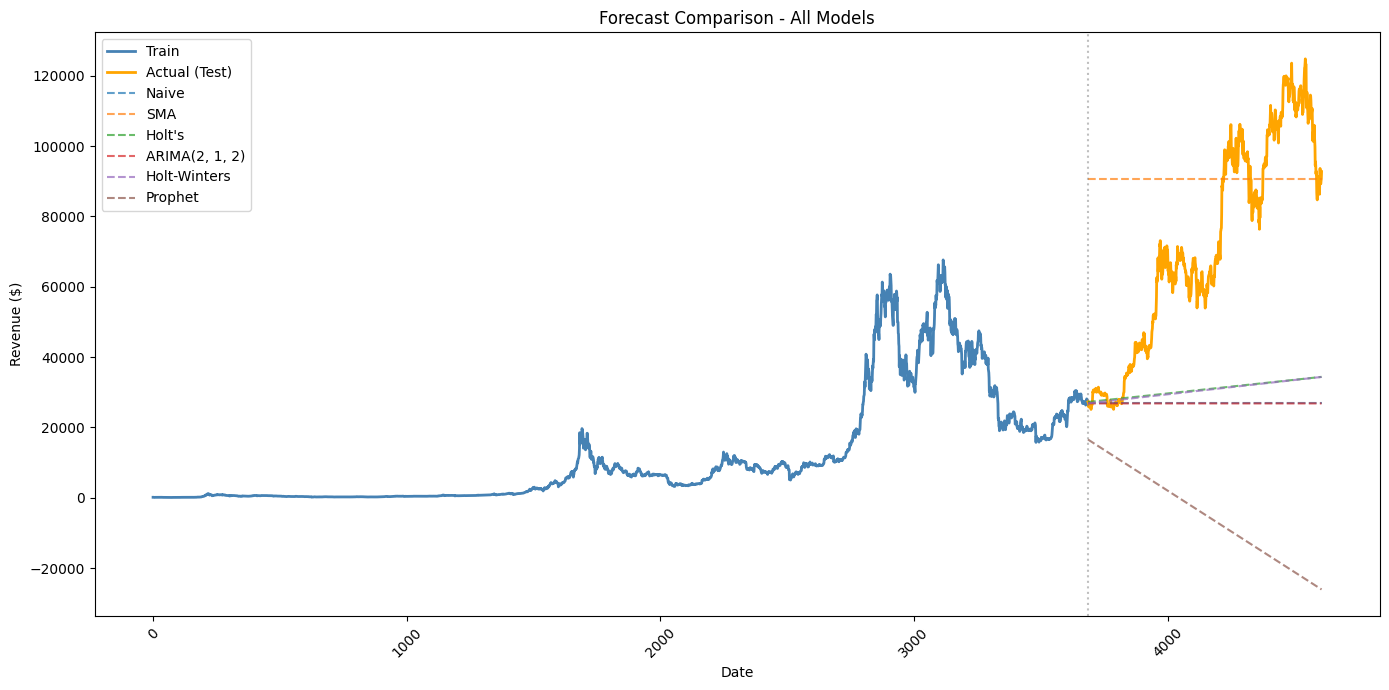

In [ ]:
# Plot all forecasts vs actual
fig, ax = plt.subplots(figsize=(14, 7))

# Plot train and test
ax.plot(train.index, train, label='Train', color='steelblue', linewidth=2)
ax.plot(test.index, test, label='Actual (Test)', color='orange', linewidth=2)

# Plot forecasts
ax.plot(test.index, naive_forecast, label='Naive', linestyle='--', alpha=0.7)
ax.plot(test.index, sma_forecast, label='SMA', linestyle='--', alpha=0.7)
ax.plot(test.index, holt_forecast, label="Holt's", linestyle='--', alpha=0.7)
ax.plot(test.index, best_arima_forecast, label=f'ARIMA{best_order}', linestyle='--', alpha=0.7)

if hw_forecast is not None:
    ax.plot(test.index, hw_forecast, label='Holt-Winters', linestyle='--', alpha=0.7)

try:
    if prophet_available and prophet_forecast is not None:
        ax.plot(test.index, prophet_forecast, label='Prophet', linestyle='--', alpha=0.7)
except:
    pass

ax.axvline(x=train.index[-1], color='grey', linestyle=':', alpha=0.5)
ax.set_title('Forecast Comparison - All Models')
ax.set_xlabel('Date')
ax.set_ylabel('Revenue ($)')
ax.legend(loc='best')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

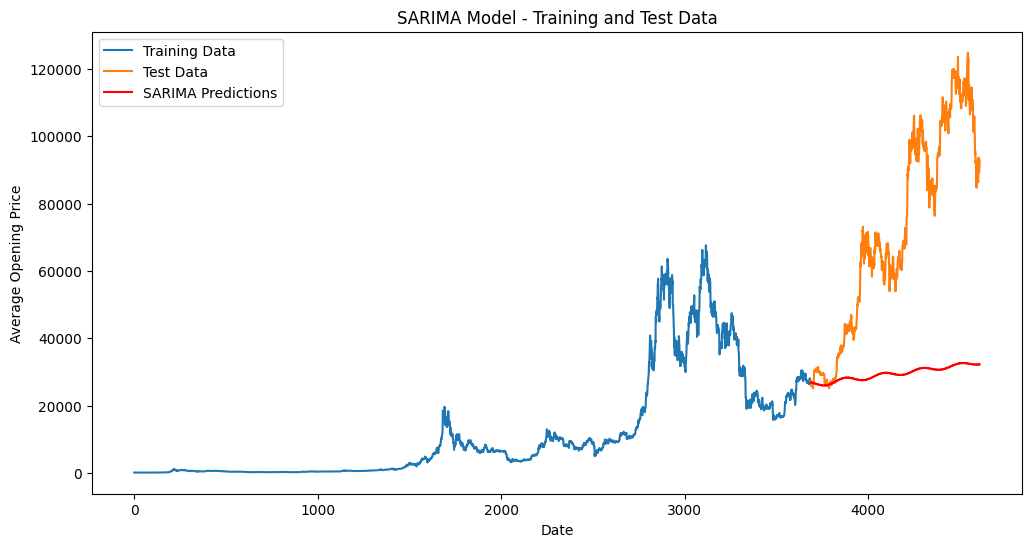

In [ ]:
model = SARIMAX(train,
                order=(2, 1, 2),
                seasonal_order=(1, 1, 1, 12))  # 12 = annual seasonality
results = model.fit()

pred_test = results.get_forecast(steps=len(test))
mean_pred = pred_test.predicted_mean
mean_pred.index = test.index  # align index

plt.figure(figsize=(12, 6))
plt.plot(train, label='Training Data')
plt.plot(test, label='Test Data')
plt.plot(mean_pred, label='SARIMA Predictions', color='red')
plt.title('SARIMA Model - Training and Test Data')
plt.xlabel('Date')
plt.ylabel('Average Opening Price')
plt.legend()
plt.show()

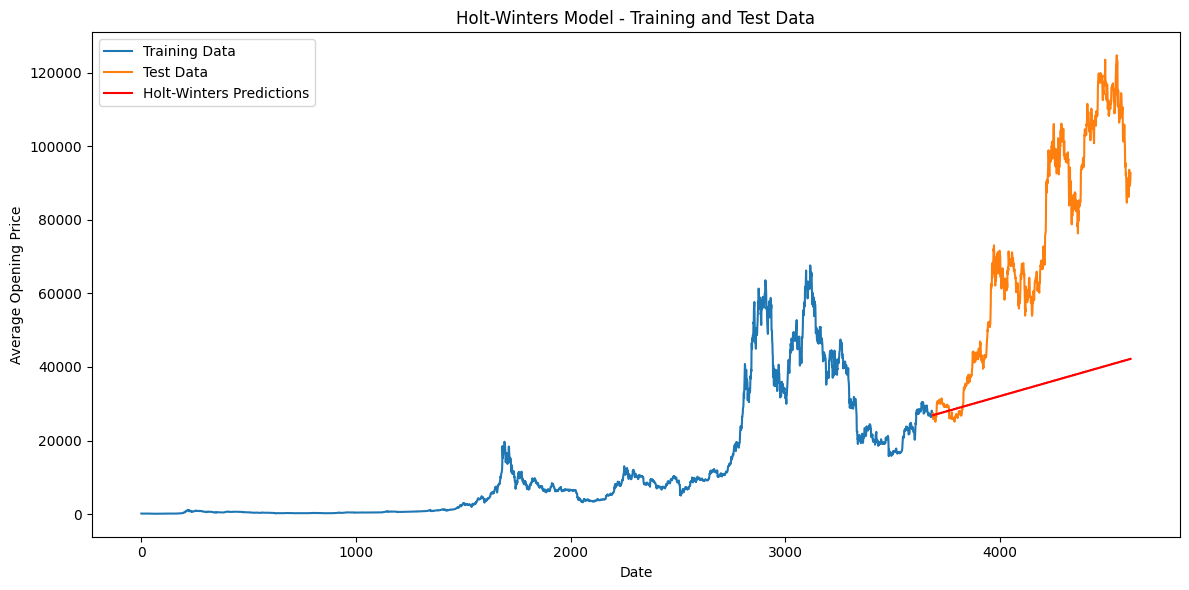

In [ ]:
# Fit Holt-Winters model
hw_model = ExponentialSmoothing(
    train,
    trend='add',              # 'add' atau 'mul'
    seasonal='add',           # 'add' atau 'mul'
    seasonal_periods=12       # musiman tahunan (bulanan)
)

hw_results = hw_model.fit()

# Forecast
hw_forecast = hw_results.forecast(steps=len(test))
hw_forecast.index = test.index  # samakan index

plt.figure(figsize=(12, 6))
plt.plot(train, label='Training Data')
plt.plot(test, label='Test Data')
plt.plot(hw_forecast, label='Holt-Winters Predictions', color='red')
plt.title('Holt-Winters Model - Training and Test Data')
plt.xlabel('Date')
plt.ylabel('Average Opening Price')
plt.legend()
plt.tight_layout()
plt.show()

# **Forecasting**

# 1. BITCOIN

**SARIMA**

In [ ]:
# Pastikan kolom 'snapped_at' sudah dalam format datetime
btc_clean['snapped_at'] = pd.to_datetime(btc_clean['snapped_at'])

# Set 'snapped_at' sebagai index
btc_clean.set_index('snapped_at', inplace=True)

# Mengambil kolom 'price' saja
btc_clean = btc_clean[['price']]

# Data bulanan (resample untuk mendapatkan data bulanan)
btc_monthly = btc_clean.resample('ME').mean()  # 'M' untuk bulanan
btc_monthly = btc_monthly.asfreq('ME')

# Data harian
btc_daily = btc_clean.resample('D').mean()  # 'D' untuk harian
btc_daily = btc_daily.asfreq('D')

# Data tahunan
btc_yearly = btc_clean.resample('YE').mean()  # 'A' untuk tahunan
btc_yearly = btc_yearly.asfreq('YE')

In [ ]:
# Fungsi untuk forecasting menggunakan SARIMA
def sarima_forecast(data, periods, freq):
    # Menentukan model SARIMA
    model = SARIMAX(data,
                    order=(1, 1, 1),
                    seasonal_order=(1, 1, 1, 12),
                    enforce_stationarity=False,
                    enforce_invertibility=False)
    # Fit model
    model_fit = model.fit(disp=False)
    # Forecasting (termasuk seluruh data yang telah ada)
    forecast = model_fit.predict(start=0, end=len(data)-1 + periods)  # Melatih dari awal hingga akhir data dan prediksi periode ke depan
    return forecast, model_fit

In [ ]:
# Fungsi untuk evaluasi model dengan menangani nilai nol pada MAPE
def evaluate_forecast(true_values, predicted_values):
    # Menghindari pembagian dengan nol pada MAPE
    # Jika ada nilai nol di true_values, set nilai tersebut menjadi kecil (misalnya, 1e-10)
    true_values_safe = np.where(true_values == 0, 1e-10, true_values)

    mae = mean_absolute_error(true_values, predicted_values)
    rmse = np.sqrt(mean_squared_error(true_values, predicted_values))
    mape = np.mean(np.abs((true_values_safe - predicted_values) / true_values_safe)) * 100
    return mae, rmse, mape

In [ ]:
forecastsarbtc_monthly, model_monthly = sarima_forecast(btc_monthly['price'], 6, 'ME')

# Menyimpan nilai prediksi bulanan ke dalam variabel
sarbtc_bulanan = forecastsarbtc_monthly[-6:]  # Menyimpan 6 nilai prediksi terakhir

# Menampilkan prediksi bulanan
print('Prediksi Bulanan:', sarbtc_bulanan)

# Evaluasi bulanan
maesarbtc_monthly, rmsesarbtc_monthly, mapesarbtc_monthly = evaluate_forecast(btc_monthly['price'][-6:], sarbtc_bulanan)
print(f'Bulanan MAE: {maesarbtc_monthly}, RMSE: {rmsesarbtc_monthly}, MAPE: {mapesarbtc_monthly}%')

Prediksi Bulanan: 2026-01-31    92088.956120
2026-02-28    93231.204582
2026-03-31    95677.074998
2026-04-30    95782.742677
2026-05-31    93216.865616
2026-06-30    92194.827560
Freq: ME, Name: predicted_mean, dtype: float64
Bulanan MAE: 14305.76371112064, RMSE: 16633.314517252675, MAPE: 12.661788682039596%


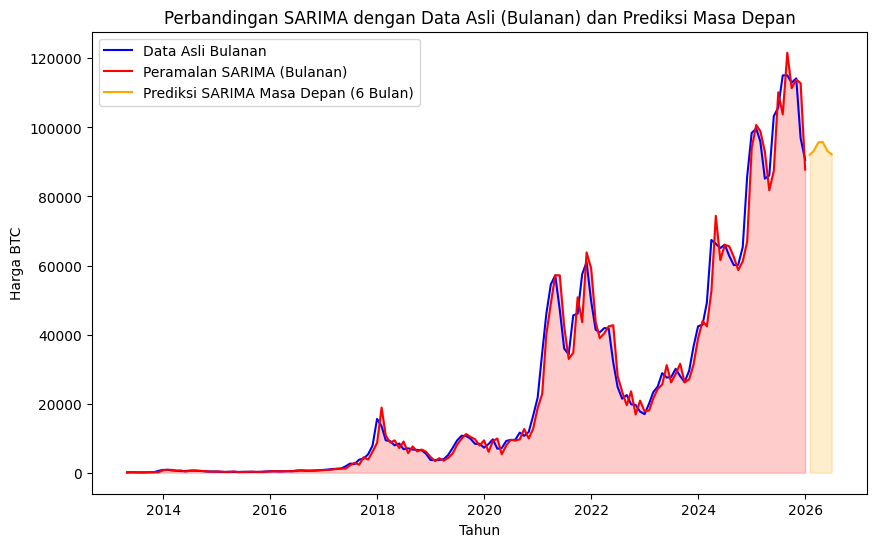

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(btc_monthly.index, btc_monthly['price'], label='Data Asli Bulanan', color='blue')

# Menampilkan prediksi SARIMA dari awal hingga titik prediksi
plt.plot(btc_monthly.index, forecastsarbtc_monthly[:len(btc_monthly)], label='Peramalan SARIMA (Bulanan)', color='red')

# Menambahkan prediksi untuk masa depan (periode ke depan)
forecast_index = pd.date_range(start=btc_monthly.index[-1], periods=7, freq='ME')[1:]  # 6 periode prediksi
plt.plot(forecast_index, forecastsarbtc_monthly[-6:], label='Prediksi SARIMA Masa Depan (6 Bulan)', color='orange')

# Mengisi area prediksi SARIMA dengan bayangan
plt.fill_between(btc_monthly.index, forecastsarbtc_monthly[:len(btc_monthly)], color='red', alpha=0.2)
plt.fill_between(forecast_index, forecastsarbtc_monthly[-6:], color='orange', alpha=0.2)

# Menambahkan label dan judul
plt.legend()
plt.title('Perbandingan SARIMA dengan Data Asli (Bulanan) dan Prediksi Masa Depan')
plt.xlabel('Tahun')
plt.ylabel('Harga BTC')
plt.show()

In [ ]:
forecastsarbtc_daily, model_daily = sarima_forecast(btc_daily['price'], 12, 'D')

# Menyimpan nilai prediksi harian ke dalam variabel
sarbtc_harian = forecastsarbtc_daily[-12:]  # Menyimpan 12 nilai prediksi terakhir

# Menampilkan prediksi harian
print('Prediksi Harian:', sarbtc_harian)

# Evaluasi harian
maesarbtc_daily, rmsesarbtc_daily, mapesarbtc_daily = evaluate_forecast(btc_daily['price'][-12:], sarbtc_harian)
print(f'Harian MAE: {maesarbtc_daily}, RMSE: {rmsesarbtc_daily}, MAPE: {mapesarbtc_daily}%')

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



Prediksi Harian: 2025-12-11    92723.460151
2025-12-12    92780.045399
2025-12-13    93006.711696
2025-12-14    93302.768286
2025-12-15    92936.265009
2025-12-16    92771.228256
2025-12-17    92775.976699
2025-12-18    93068.772722
2025-12-19    93066.563712
2025-12-20    93113.544783
2025-12-21    93190.486820
2025-12-22    92979.441258
Freq: D, Name: predicted_mean, dtype: float64
Harian MAE: 2480.930967212173, RMSE: 3038.1492406553834, MAPE: 2.776457751906213%


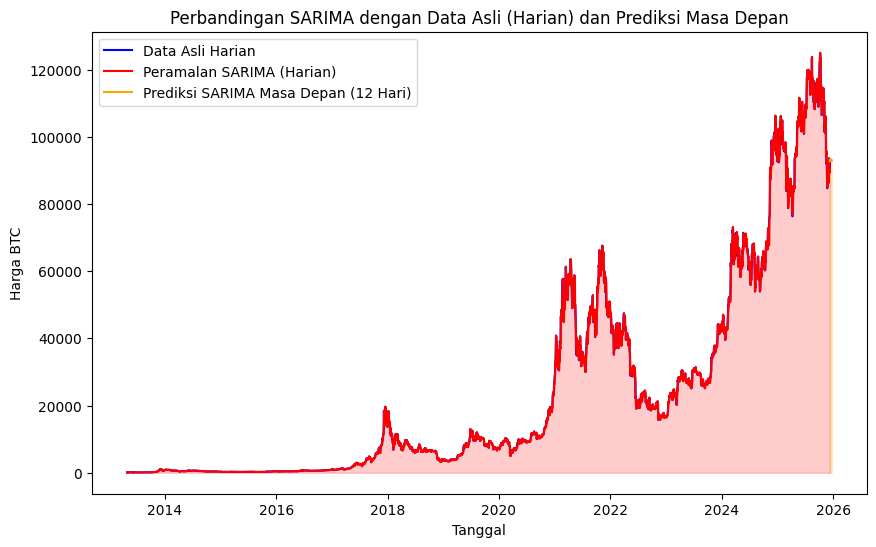

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(btc_daily.index, btc_daily['price'], label='Data Asli Harian', color='blue')

# Menampilkan prediksi SARIMA dari awal hingga titik prediksi
plt.plot(btc_daily.index, forecastsarbtc_daily[:len(btc_daily)], label='Peramalan SARIMA (Harian)', color='red')

# Menambahkan prediksi untuk masa depan (periode ke depan)
forecast_index_daily = pd.date_range(start=btc_daily.index[-1], periods=13, freq='D')[1:]  # 12 periode prediksi
plt.plot(forecast_index_daily, forecastsarbtc_daily[-12:], label='Prediksi SARIMA Masa Depan (12 Hari)', color='orange')

# Mengisi area prediksi SARIMA dengan bayangan
plt.fill_between(btc_daily.index, forecastsarbtc_daily[:len(btc_daily)], color='red', alpha=0.2)
plt.fill_between(forecast_index_daily, forecastsarbtc_daily[-12:], color='orange', alpha=0.2)

# Menambahkan label dan judul
plt.legend()
plt.title('Perbandingan SARIMA dengan Data Asli (Harian) dan Prediksi Masa Depan')
plt.xlabel('Tanggal')
plt.ylabel('Harga BTC')
plt.show()

In [ ]:
forecastsarbtc_yearly, model_yearly = sarima_forecast(btc_yearly['price'], 3, 'A-DEC')

# Menampilkan prediksi tahunan
sarbtc_tahunan = forecastsarbtc_yearly[-3:]
print('Prediksi Tahunan:', sarbtc_tahunan)

# Evaluasi
maesarbtc_yearly, rmsesarbtc_yearly, mapesarbtc_yearly = evaluate_forecast(btc_yearly['price'][-3:], sarbtc_tahunan)
print(f'Tahunan MAE: {maesarbtc_yearly}, RMSE: {rmsesarbtc_yearly}, MAPE: {mapesarbtc_yearly}%')

Prediksi Tahunan: 2026-12-31    102735.779429
2027-12-31    102482.007505
2028-12-31    102777.037238
Freq: YE-DEC, Name: predicted_mean, dtype: float64
Tahunan MAE: 36966.14556560594, RMSE: 47645.952868432454, MAPE: 104.25333787884436%


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning:

Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning:

Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.



/tmp/ipython-input-1025894594.py:4: FutureWarning:

'A-DEC' is deprecated and will be removed in a future version, please use 'YE-DEC' instead.



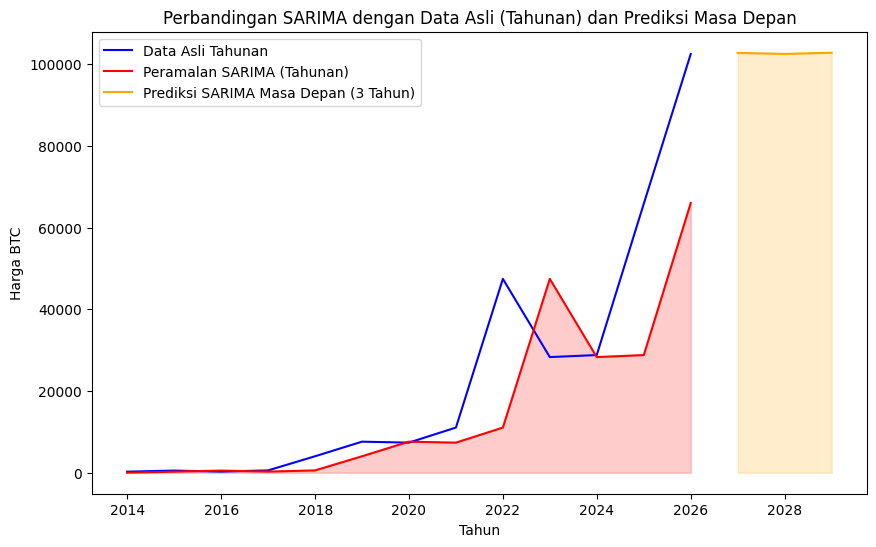

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(btc_yearly.index, btc_yearly['price'], label='Data Asli Tahunan', color='blue')
plt.plot(btc_yearly.index, forecastsarbtc_yearly[:len(btc_yearly)], label='Peramalan SARIMA (Tahunan)', color='red')
forecast_index_yearly = pd.date_range(start=btc_yearly.index[-1], periods=4, freq='A-DEC')[1:]
plt.plot(forecast_index_yearly, forecastsarbtc_yearly[-3:], label='Prediksi SARIMA Masa Depan (3 Tahun)', color='orange')
plt.fill_between(btc_yearly.index, forecastsarbtc_yearly[:len(btc_yearly)], color='red', alpha=0.2)
plt.fill_between(forecast_index_yearly, forecastsarbtc_yearly[-3:], color='orange', alpha=0.2)
plt.legend()
plt.title('Perbandingan SARIMA dengan Data Asli (Tahunan) dan Prediksi Masa Depan')
plt.xlabel('Tahun')
plt.ylabel('Harga BTC')
plt.show()

**HOLT-WINTERS**

In [ ]:
# Fungsi untuk forecasting menggunakan Holt-Winters
def holt_winters_forecast(data, periods, seasonal_periods):
    # Menentukan model Holt-Winters
    model = ExponentialSmoothing(data,
                                 trend='add',
                                 seasonal='add' if seasonal_periods > 1 else None,
                                 seasonal_periods=seasonal_periods if seasonal_periods > 1 else None,
                                 damped_trend=False,
                                 initialization_method='estimated')
    # Fit model
    model_fit = model.fit()
    # Forecasting (termasuk seluruh data yang telah ada)
    forecast = model_fit.forecast(periods)  # Melatih dari awal hingga akhir data dan prediksi periode ke depan
    return forecast, model_fit

In [ ]:
hotbtc_bulanan, model_monthly = holt_winters_forecast(btc_monthly['price'], 6, 12)

# Menyimpan nilai prediksi bulanan ke dalam variabel
hotbtc_bulanan = hotbtc_bulanan[-6:]  # Menyimpan 6 nilai prediksi terakhir

# Menampilkan prediksi bulanan
print('Prediksi Bulanan:', hotbtc_bulanan)

# Evaluasi bulanan (gunakan data yang sesuai untuk evaluasi)
mae_hotbtc_bulanan, rmse_hotbtc_bulanan, mape_hotbtc_bulanan = evaluate_forecast(btc_monthly['price'][-6:], hotbtc_bulanan)
print(f'Bulanan MAE: {mae_hotbtc_bulanan}, RMSE: {rmse_hotbtc_bulanan}, MAPE: {mape_hotbtc_bulanan}%')

Prediksi Bulanan: 2026-01-31    91168.178161
2026-02-28    91795.075554
2026-03-31    92499.227862
2026-04-30    93053.934620
2026-05-31    93826.239370
2026-06-30    94274.857012
Freq: ME, dtype: float64
Bulanan MAE: 15928.133357655757, RMSE: 18270.53555410759, MAPE: 14.148112530312037%


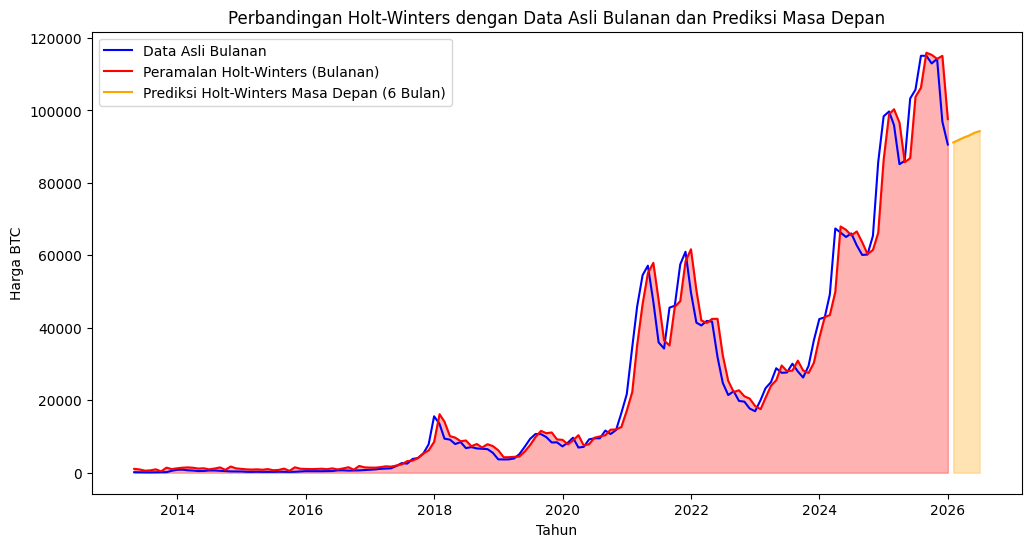

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(btc_monthly.index, btc_monthly['price'], label='Data Asli Bulanan', color='blue')  # Data asli
plt.plot(btc_monthly.index, model_monthly.fittedvalues, label='Peramalan Holt-Winters (Bulanan)', color='red')  # Peramalan Holt-Winters
plt.plot(pd.date_range(btc_monthly.index[-1], periods=7, freq='ME')[1:], hotbtc_bulanan, label='Prediksi Holt-Winters Masa Depan (6 Bulan)', color='orange')  # Prediksi Masa Depan
plt.fill_between(pd.date_range(btc_monthly.index[-1], periods=7, freq='ME')[1:], hotbtc_bulanan, color='orange', alpha=0.3)  # Area bayangan untuk prediksi

# Menambahkan bayangan pada garis Holt-Winters
plt.fill_between(btc_monthly.index, model_monthly.fittedvalues, color='red', alpha=0.3)  # Area bayangan untuk Holt-Winters

# Menambahkan label dan judul
plt.title('Perbandingan Holt-Winters dengan Data Asli Bulanan dan Prediksi Masa Depan')
plt.xlabel('Tahun')
plt.ylabel('Harga BTC')
plt.legend()
plt.show()

In [ ]:
btc_daily_cleaned = btc_daily.dropna()

# Forecasting menggunakan Holt-Winters untuk data harian dengan prediksi 12 hari ke depan
hotbtc_harian, model_daily = holt_winters_forecast(btc_daily_cleaned['price'], 12, 7)  # 12 untuk prediksi 12 hari, 7 untuk musiman mingguan

# Menyimpan nilai prediksi harian ke dalam variabel
hotbtc_harian_predictions = hotbtc_harian  # Menyimpan semua prediksi untuk penggunaan lebih lanjut

# Menampilkan nilai prediksi harian
print('Prediksi Harian:', hotbtc_harian_predictions)

# Evaluasi model harian (gunakan data yang sesuai untuk evaluasi)
mae_hotbtc_harian, rmse_hotbtc_harian, mape_hotbtc_harian = evaluate_forecast(btc_daily['price'][-6:], hotbtc_harian_predictions[:6])
print(f'Harian MAE: {mae_hotbtc_harian}, RMSE: {rmse_hotbtc_harian}, MAPE: {mape_hotbtc_harian}%')

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.



Prediksi Harian: 4608    92854.226388
4609    92649.735525
4610    92692.138667
4611    92755.874484
4612    92837.406637
4613    92868.622204
4614    92799.144363
4615    93002.282353
4616    92797.791489
4617    92840.194631
4618    92903.930448
4619    92985.462601
dtype: float64
Harian MAE: 2076.878616479718, RMSE: 2423.3908593033866, MAPE: 2.3103167017180875%


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning:

No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.



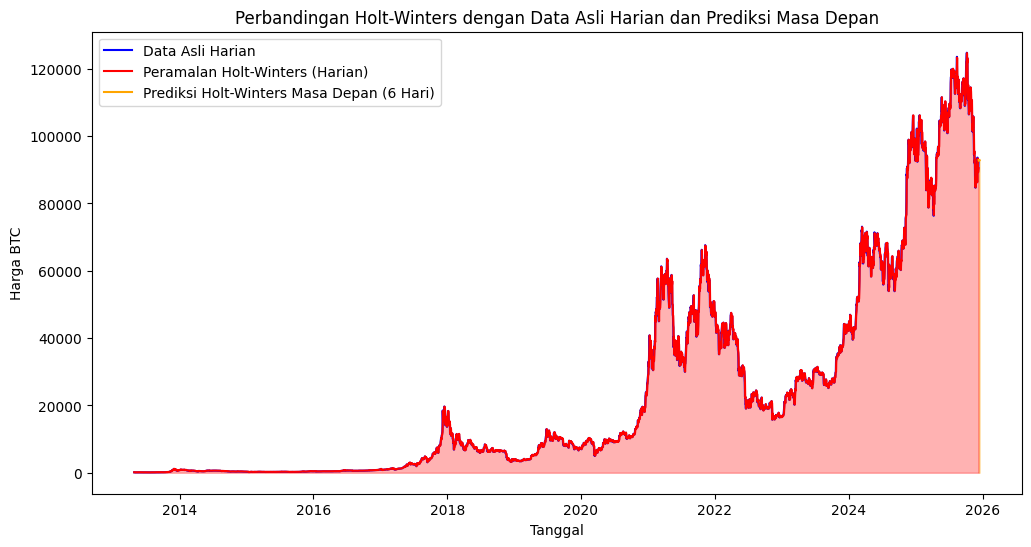

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(btc_daily.index, btc_daily['price'], label='Data Asli Harian', color='blue')
plt.plot(btc_daily.index, model_daily.fittedvalues, label='Peramalan Holt-Winters (Harian)', color='red')
plt.plot(pd.date_range(btc_daily.index[-1], periods=7, freq='D')[1:], hotbtc_daily_predictions, label='Prediksi Holt-Winters Masa Depan (6 Hari)', color='orange')
plt.fill_between(pd.date_range(btc_daily.index[-1], periods=7, freq='D')[1:], hotbtc_daily_predictions, color='orange', alpha=0.3)

# Menambahkan bayangan pada garis Holt-Winters
plt.fill_between(btc_daily.index, model_daily.fittedvalues, color='red', alpha=0.3)

# Menambahkan label dan judul
plt.title('Perbandingan Holt-Winters dengan Data Asli Harian dan Prediksi Masa Depan')
plt.xlabel('Tanggal')
plt.ylabel('Harga BTC')
plt.legend()
plt.show()

In [ ]:
hotbtc_yearly, model_yearly = holt_winters_forecast(btc_yearly['price'], 3, 1)  # 3 untuk prediksi 3 tahun, 1 untuk musiman tahunan

# Menyimpan nilai prediksi tahunan ke dalam variabel
hotbtc_tahunan = hotbtc_yearly  # Menyimpan semua prediksi untuk penggunaan lebih lanjut

# Menampilkan nilai prediksi tahunan
print('Prediksi Tahunan:', hotbtc_tahunan)

# Evaluasi model tahunan (gunakan data yang sesuai untuk evaluasi)
mae_hotbtc_yearly, rmse_hotbtc_yearly, mape_hotbtc_yearly = evaluate_forecast(btc_yearly['price'][-3:], hotbtc_tahunan)
print(f'Tahunan MAE: {mae_hotbtc_yearly}, RMSE: {rmse_hotbtc_yearly}, MAPE: {mape_hotbtc_yearly}%')

Prediksi Tahunan: 2026-12-31    111188.199368
2027-12-31    119909.873371
2028-12-31    128631.547373
Freq: YE-DEC, dtype: float64
Tahunan MAE: 54211.07754574868, RMSE: 58871.04989286861, MAPE: 131.27284936492634%


/tmp/ipython-input-190683056.py:4: FutureWarning:

'A-DEC' is deprecated and will be removed in a future version, please use 'YE-DEC' instead.

/tmp/ipython-input-190683056.py:5: FutureWarning:

'A-DEC' is deprecated and will be removed in a future version, please use 'YE-DEC' instead.



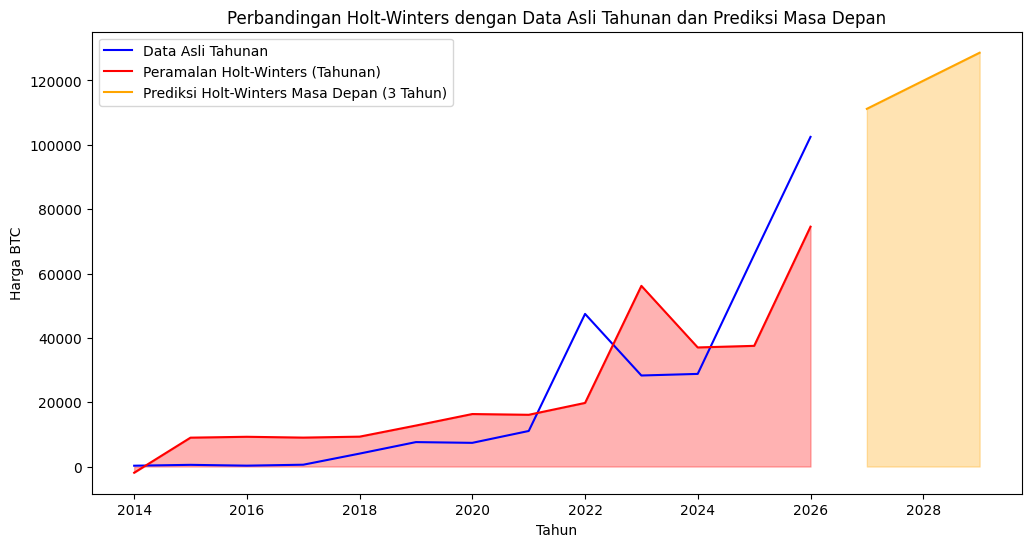

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(btc_yearly.index, btc_yearly['price'], label='Data Asli Tahunan', color='blue')  # Data asli
plt.plot(btc_yearly.index, model_yearly.fittedvalues, label='Peramalan Holt-Winters (Tahunan)', color='red')  # Peramalan Holt-Winters
plt.plot(pd.date_range(btc_yearly.index[-1], periods=4, freq='A-DEC')[1:], hotbtc_yearly_predictions, label='Prediksi Holt-Winters Masa Depan (3 Tahun)', color='orange')  # Prediksi Masa Depan
plt.fill_between(pd.date_range(btc_yearly.index[-1], periods=4, freq='A-DEC')[1:], hotbtc_yearly_predictions, color='orange', alpha=0.3)  # Area bayangan untuk prediksi

# Menambahkan bayangan pada garis Holt-Winters
plt.fill_between(btc_yearly.index, model_yearly.fittedvalues, color='red', alpha=0.3)  # Area bayangan untuk Holt-Winters

# Menambahkan label dan judul
plt.title('Perbandingan Holt-Winters dengan Data Asli Tahunan dan Prediksi Masa Depan')
plt.xlabel('Tahun')
plt.ylabel('Harga BTC')
plt.legend()
plt.show()

# 2. ETHEREUM

**SARIMA**

In [ ]:
# Pastikan kolom 'snapped_at' sudah dalam format datetime
eth_clean['snapped_at'] = pd.to_datetime(eth_clean['snapped_at'])

# Set 'snapped_at' sebagai index
eth_clean.set_index('snapped_at', inplace=True)

# Mengambil kolom 'price' saja
eth_clean = eth_clean[['price']]

# Data bulanan (resample untuk mendapatkan data bulanan)
eth_monthly = eth_clean.resample('ME').mean()  # 'M' untuk bulanan
eth_monthly = eth_monthly.asfreq('ME')

# Data harian
eth_daily = eth_clean.resample('D').mean()  # 'D' untuk harian
eth_daily = eth_daily.asfreq('D')

# Data tahunan
eth_yearly = eth_clean.resample('YE').mean()  # 'A' untuk tahunan
eth_yearly = eth_yearly.asfreq('YE')

In [ ]:
# Forecasting menggunakan SARIMA untuk data bulanan Ethereum
forecasteth_monthly, model_monthly = sarima_forecast(eth_monthly['price'], 6, 'ME')

# Menyimpan nilai prediksi bulanan ke dalam variabel
sareth_bulanan = forecasteth_monthly[-6:]  # Menyimpan 6 nilai prediksi terakhir

# Menampilkan prediksi bulanan
print('Prediksi Bulanan:', sareth_bulanan)

# Evaluasi bulanan
mae_eth_monthly, rmse_eth_monthly, mape_eth_monthly = evaluate_forecast(eth_monthly['price'][-6:], sareth_bulanan)
print(f'Bulanan MAE: {mae_eth_monthly}, RMSE: {rmse_eth_monthly}, MAPE: {mape_eth_monthly}%')

Prediksi Bulanan: 2026-01-31    3317.533177
2026-02-28    3379.926055
2026-03-31    3499.355703
2026-04-30    3583.224360
2026-05-31    3585.764912
2026-06-30    3436.248626
Freq: ME, Name: predicted_mean, dtype: float64
Bulanan MAE: 513.4389908176543, RMSE: 577.7323001676077, MAPE: 13.249497998894865%


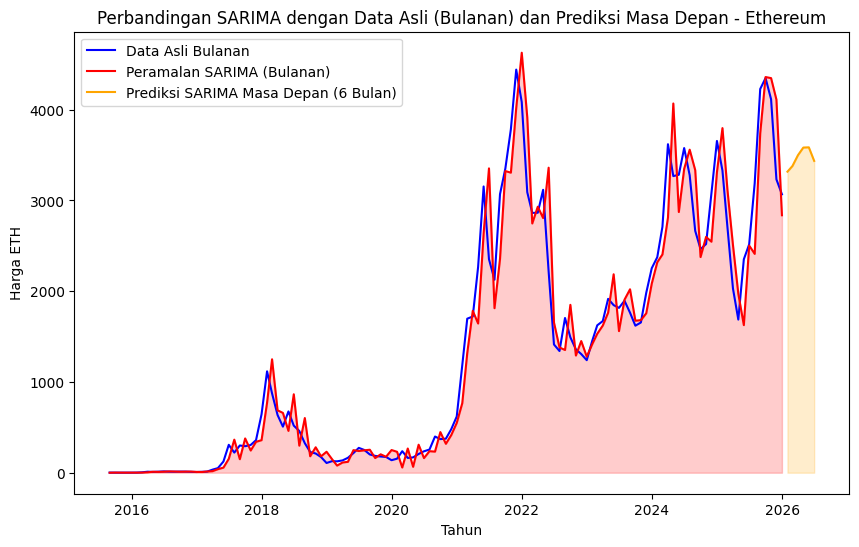

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(eth_monthly.index, eth_monthly['price'], label='Data Asli Bulanan', color='blue')  # Data asli Ethereum

# Menampilkan prediksi SARIMA dari awal hingga titik prediksi
plt.plot(eth_monthly.index, forecasteth_monthly[:len(eth_monthly)], label='Peramalan SARIMA (Bulanan)', color='red')  # Peramalan SARIMA untuk Ethereum

# Menambahkan prediksi untuk masa depan (periode ke depan)
forecast_index = pd.date_range(start=eth_monthly.index[-1], periods=7, freq='ME')[1:]  # 6 periode prediksi untuk Ethereum
plt.plot(forecast_index, forecasteth_monthly[-6:], label='Prediksi SARIMA Masa Depan (6 Bulan)', color='orange')

# Mengisi area prediksi SARIMA dengan bayangan
plt.fill_between(eth_monthly.index, forecasteth_monthly[:len(eth_monthly)], color='red', alpha=0.2)
plt.fill_between(forecast_index, forecasteth_monthly[-6:], color='orange', alpha=0.2)

# Menambahkan label dan judul
plt.legend()
plt.title('Perbandingan SARIMA dengan Data Asli (Bulanan) dan Prediksi Masa Depan - Ethereum')
plt.xlabel('Tahun')
plt.ylabel('Harga ETH')
plt.show()

In [ ]:
# Forecasting menggunakan SARIMA untuk data harian Ethereum
forecasteth_daily, model_daily = sarima_forecast(eth_daily['price'], 12, 'D')

# Menyimpan nilai prediksi harian ke dalam variabel
sareth_harian = forecasteth_daily[-12:]  # Menyimpan 12 nilai prediksi terakhir

# Menampilkan prediksi harian
print('Prediksi Harian:', sareth_harian)

# Evaluasi harian
maeeth_daily, rmseeth_daily, mapeeth_daily = evaluate_forecast(eth_daily['price'][-12:], sareth_harian)
print(f'Harian MAE: {maeeth_daily}, RMSE: {rmseeth_daily}, MAPE: {mapeeth_daily}%')

Prediksi Harian: 2025-12-11    3318.202610
2025-12-12    3324.909922
2025-12-13    3326.257012
2025-12-14    3340.677207
2025-12-15    3329.697802
2025-12-16    3314.158964
2025-12-17    3312.364711
2025-12-18    3326.788079
2025-12-19    3326.247126
2025-12-20    3329.292386
2025-12-21    3329.786423
2025-12-22    3314.712360
Freq: D, Name: predicted_mean, dtype: float64
Harian MAE: 267.0606917932034, RMSE: 295.48124100547943, MAPE: 8.911462567946653%


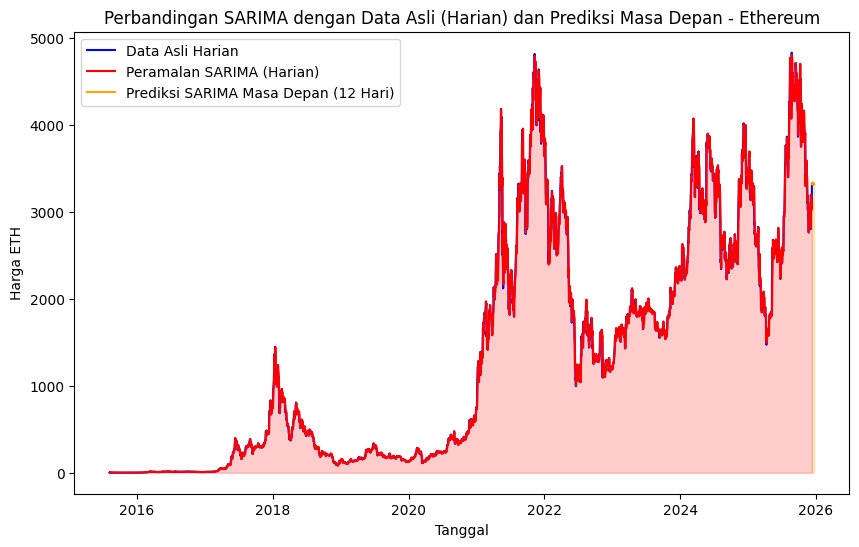

In [ ]:
# Grafik perbandingan antara data asli, Holt-Winters, dan prediksi masa depan
plt.figure(figsize=(10, 6))
plt.plot(eth_daily.index, eth_daily['price'], label='Data Asli Harian', color='blue')

# Menampilkan prediksi SARIMA dari awal hingga titik prediksi
plt.plot(eth_daily.index, forecasteth_daily[:len(eth_daily)], label='Peramalan SARIMA (Harian)', color='red')

# Menambahkan prediksi untuk masa depan (periode ke depan)
forecast_index_daily = pd.date_range(start=eth_daily.index[-1], periods=13, freq='D')[1:]  # 12 periode prediksi
plt.plot(forecast_index_daily, forecasteth_daily[-12:], label='Prediksi SARIMA Masa Depan (12 Hari)', color='orange')

# Mengisi area prediksi SARIMA dengan bayangan
plt.fill_between(eth_daily.index, forecasteth_daily[:len(eth_daily)], color='red', alpha=0.2)
plt.fill_between(forecast_index_daily, forecasteth_daily[-12:], color='orange', alpha=0.2)

# Menambahkan label dan judul
plt.legend()
plt.title('Perbandingan SARIMA dengan Data Asli (Harian) dan Prediksi Masa Depan - Ethereum')
plt.xlabel('Tanggal')
plt.ylabel('Harga ETH')
plt.show()

In [ ]:
# Forecasting menggunakan SARIMA untuk data tahunan Ethereum
forecasteth_yearly, model_yearly = sarima_forecast(eth_yearly['price'], 3, 'A-DEC')

# Menampilkan prediksi tahunan
sareth_tahunan = forecasteth_yearly[-3:]
print('Prediksi Tahunan:', sareth_tahunan)

# Evaluasi
maeeth_yearly, rmseeth_yearly, mapeeth_yearly = evaluate_forecast(eth_yearly['price'][-3:], sareth_tahunan)
print(f'Tahunan MAE: {maeeth_yearly}, RMSE: {rmseeth_yearly}, MAPE: {mapeeth_yearly}%')

Prediksi Tahunan: 2026-12-31    3071.613765
2027-12-31    3072.245948
2028-12-31    3081.051216
Freq: YE-DEC, Name: predicted_mean, dtype: float64
Tahunan MAE: 439.36581681919034, RMSE: 738.6767158421708, MAPE: 24.211135282659278%


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning:

Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning:

Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.



/tmp/ipython-input-1665077040.py:5: FutureWarning:

'A-DEC' is deprecated and will be removed in a future version, please use 'YE-DEC' instead.



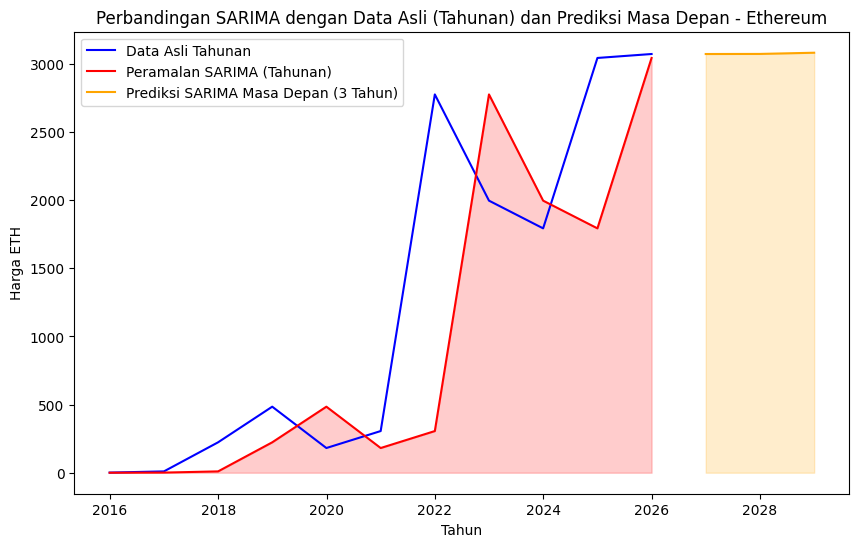

In [ ]:
# Grafik perbandingan antara data asli, SARIMA, dan prediksi masa depan
plt.figure(figsize=(10, 6))
plt.plot(eth_yearly.index, eth_yearly['price'], label='Data Asli Tahunan', color='blue')
plt.plot(eth_yearly.index, forecasteth_yearly[:len(eth_yearly)], label='Peramalan SARIMA (Tahunan)', color='red')
forecast_index_yearly = pd.date_range(start=eth_yearly.index[-1], periods=4, freq='A-DEC')[1:]
plt.plot(forecast_index_yearly, forecasteth_yearly[-3:], label='Prediksi SARIMA Masa Depan (3 Tahun)', color='orange')
plt.fill_between(eth_yearly.index, forecasteth_yearly[:len(eth_yearly)], color='red', alpha=0.2)
plt.fill_between(forecast_index_yearly, forecasteth_yearly[-3:], color='orange', alpha=0.2)
plt.legend()
plt.title('Perbandingan SARIMA dengan Data Asli (Tahunan) dan Prediksi Masa Depan - Ethereum')
plt.xlabel('Tahun')
plt.ylabel('Harga ETH')
plt.show()

**HOLT-WINTERS**

In [ ]:
hoteth_bulanan, model_monthly = holt_winters_forecast(eth_monthly['price'], 6, 12)

# Menyimpan nilai prediksi bulanan ke dalam variabel
hoteth_bulanan = hoteth_bulanan[-6:]  # Menyimpan 6 nilai prediksi terakhir

# Menampilkan prediksi bulanan
print('Prediksi Bulanan:', hoteth_bulanan)

# Evaluasi bulanan (gunakan data yang sesuai untuk evaluasi)
mae_hoteth_bulanan, rmse_hoteth_bulanan, mape_hoteth_bulanan = evaluate_forecast(eth_monthly['price'][-6:], hoteth_bulanan)
print(f'Bulanan MAE: {mae_hoteth_bulanan}, RMSE: {rmse_hoteth_bulanan}, MAPE: {mape_hoteth_bulanan}%')

Prediksi Bulanan: 2026-01-31    3076.723599
2026-02-28    3077.314542
2026-03-31    3080.551749
2026-04-30    3108.107578
2026-05-31    3201.135023
2026-06-30    3095.220495
Freq: ME, dtype: float64
Bulanan MAE: 599.8206396651855, RMSE: 812.8638560622342, MAPE: 14.37875738222489%


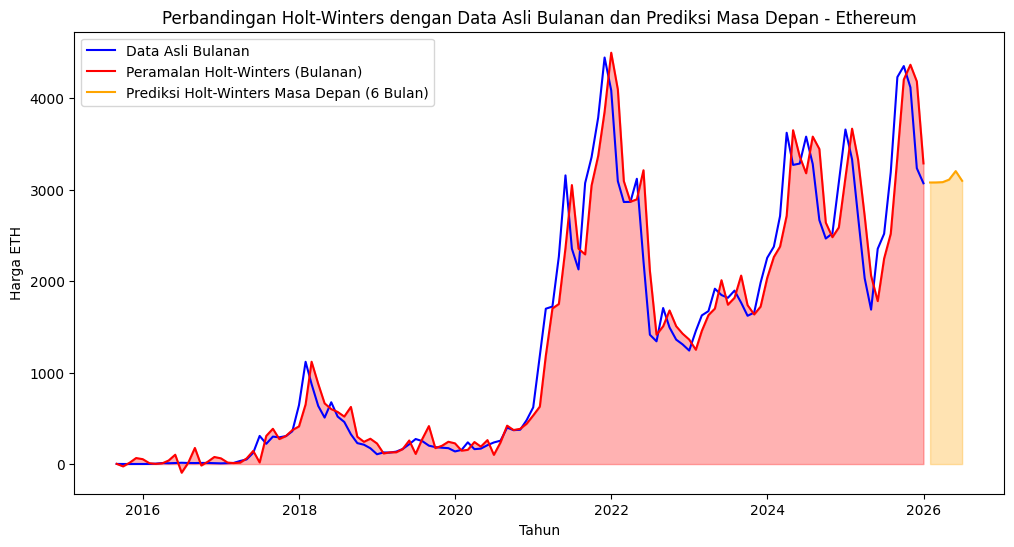

In [ ]:
# Grafik perbandingan antara data asli, Holt-Winters, dan prediksi masa depan
plt.figure(figsize=(12, 6))
plt.plot(eth_monthly.index, eth_monthly['price'], label='Data Asli Bulanan', color='blue')  # Data asli
plt.plot(eth_monthly.index, model_monthly.fittedvalues, label='Peramalan Holt-Winters (Bulanan)', color='red')  # Peramalan Holt-Winters
plt.plot(pd.date_range(eth_monthly.index[-1], periods=7, freq='ME')[1:], hoteth_bulanan, label='Prediksi Holt-Winters Masa Depan (6 Bulan)', color='orange')  # Prediksi Masa Depan
plt.fill_between(pd.date_range(eth_monthly.index[-1], periods=7, freq='ME')[1:], hoteth_bulanan, color='orange', alpha=0.3)  # Area bayangan untuk prediksi

# Menambahkan bayangan pada garis Holt-Winters
plt.fill_between(eth_monthly.index, model_monthly.fittedvalues, color='red', alpha=0.3)  # Area bayangan untuk Holt-Winters

# Menambahkan label dan judul
plt.title('Perbandingan Holt-Winters dengan Data Asli Bulanan dan Prediksi Masa Depan - Ethereum')
plt.xlabel('Tahun')
plt.ylabel('Harga ETH')
plt.legend()
plt.show()

In [ ]:
# Menghapus nilai NaN jika ada
eth_daily_cleaned = eth_daily.dropna()

# Forecasting menggunakan Holt-Winters untuk data harian dengan prediksi 12 hari ke depan
hoteth_harian, model_daily = holt_winters_forecast(eth_daily_cleaned['price'], 12, 7)  # 12 untuk prediksi 12 hari, 7 untuk musiman mingguan

# Menyimpan nilai prediksi harian ke dalam variabel
hoteth_harian_predictions = hoteth_harian  # Menyimpan semua prediksi untuk penggunaan lebih lanjut

# Menampilkan nilai prediksi harian
print('Prediksi Harian:', hoteth_harian_predictions)

# Evaluasi model harian (gunakan data yang sesuai untuk evaluasi)
mae_hoteth_harian, rmse_hoteth_harian, mape_hoteth_harian = evaluate_forecast(eth_daily['price'][-6:], hoteth_harian_predictions[:6])
print(f'Harian MAE: {mae_hoteth_harian}, RMSE: {rmse_hoteth_harian}, MAPE: {mape_hoteth_harian}%')

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning:

No supported index is available. Prediction results will be given with an integer index beginning at `start`.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning:

No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.



Prediksi Harian: 3778    3321.393224
3779    3317.248200
3780    3316.204150
3781    3319.326605
3782    3322.963648
3783    3324.070155
3784    3320.922194
3785    3327.545524
3786    3323.400500
3787    3322.356450
3788    3325.478905
3789    3329.115948
dtype: float64
Harian MAE: 204.12095671538637, RMSE: 226.81294172759658, MAPE: 6.656790182546082%


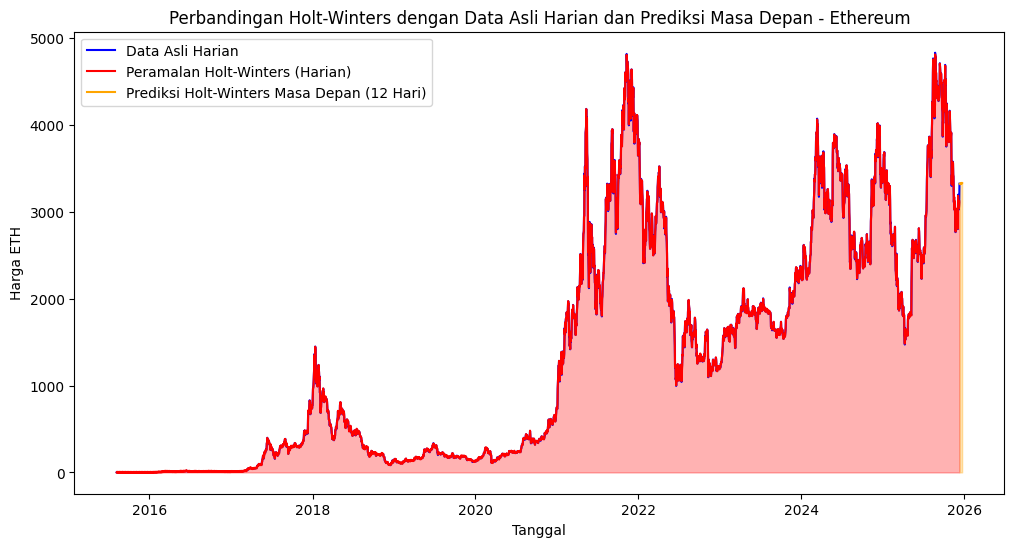

In [ ]:
plt.figure(figsize=(12, 6))

# Plot data asli Ethereum
plt.plot(eth_daily.index, eth_daily['price'], label='Data Asli Harian', color='blue')

# Menampilkan peramalan Holt-Winters (hanya untuk data historis)
plt.plot(eth_daily.index[:len(model_daily.fittedvalues)], model_daily.fittedvalues, label='Peramalan Holt-Winters (Harian)', color='red')
forecast_index_daily = pd.date_range(start=eth_daily.index[-1], periods=13, freq='D')[1:]  # 12 periode prediksi
plt.plot(forecast_index_daily, hoteth_harian_predictions, label='Prediksi Holt-Winters Masa Depan (12 Hari)', color='orange')
plt.fill_between(eth_daily.index[:len(model_daily.fittedvalues)], model_daily.fittedvalues, color='red', alpha=0.3)
plt.fill_between(forecast_index_daily, hoteth_harian_predictions, color='orange', alpha=0.3)

# Menambahkan label dan judul
plt.title('Perbandingan Holt-Winters dengan Data Asli Harian dan Prediksi Masa Depan - Ethereum')
plt.xlabel('Tanggal')
plt.ylabel('Harga ETH')
plt.legend()
plt.show()

In [ ]:
# Forecasting menggunakan Holt-Winters untuk data tahunan Ethereum
hoteth_yearly, model_yearly = holt_winters_forecast(eth_yearly['price'], 3, 1)  # 3 untuk prediksi 3 tahun, 1 untuk musiman tahunan

# Menyimpan nilai prediksi tahunan ke dalam variabel
hoteth_tahunan = hoteth_yearly  # Menyimpan semua prediksi untuk penggunaan lebih lanjut

# Menampilkan nilai prediksi tahunan
print('Prediksi Tahunan:', hoteth_tahunan)

# Evaluasi model tahunan (gunakan data yang sesuai untuk evaluasi)
mae_hoteth_yearly, rmse_hoteth_yearly, mape_hoteth_yearly = evaluate_forecast(eth_yearly['price'][-3:], hoteth_tahunan)
print(f'Tahunan MAE: {mae_hoteth_yearly}, RMSE: {rmse_hoteth_yearly}, MAPE: {mape_hoteth_yearly}%')

Prediksi Tahunan: 2026-12-31    3324.454900
2027-12-31    3668.183831
2028-12-31    4011.912761
Freq: YE-DEC, dtype: float64
Tahunan MAE: 1032.5793378138812, RMSE: 1098.8113712759932, MAPE: 45.543311204520535%


/tmp/ipython-input-3456571538.py:5: FutureWarning:

'A-DEC' is deprecated and will be removed in a future version, please use 'YE-DEC' instead.

/tmp/ipython-input-3456571538.py:6: FutureWarning:

'A-DEC' is deprecated and will be removed in a future version, please use 'YE-DEC' instead.



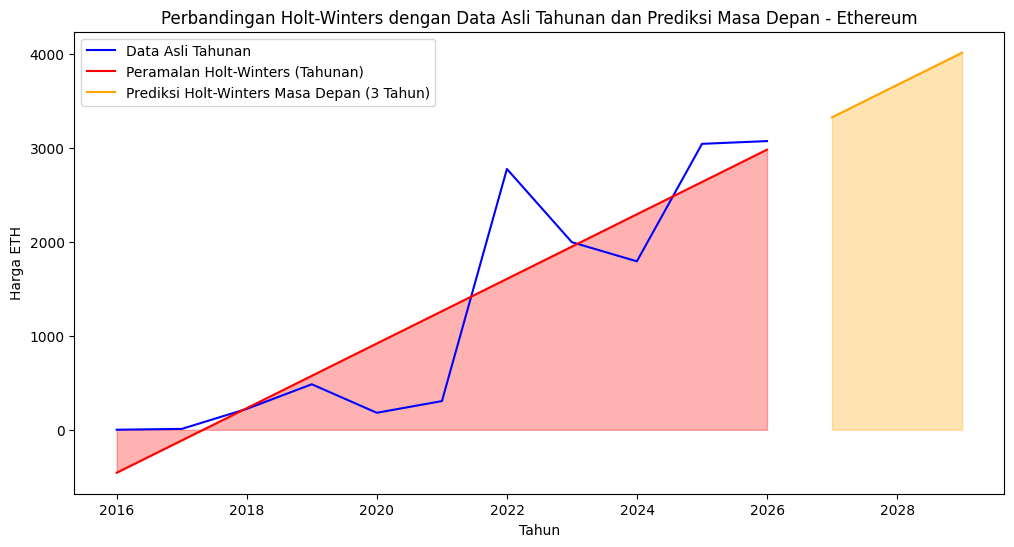

In [ ]:
# Grafik perbandingan antara data asli, Holt-Winters, dan prediksi masa depan
plt.figure(figsize=(12, 6))
plt.plot(eth_yearly.index, eth_yearly['price'], label='Data Asli Tahunan', color='blue')  # Data asli Ethereum
plt.plot(eth_yearly.index, model_yearly.fittedvalues, label='Peramalan Holt-Winters (Tahunan)', color='red')  # Peramalan Holt-Winters
plt.plot(pd.date_range(eth_yearly.index[-1], periods=4, freq='A-DEC')[1:], hoteth_yearly_predictions, label='Prediksi Holt-Winters Masa Depan (3 Tahun)', color='orange')  # Prediksi Masa Depan
plt.fill_between(pd.date_range(eth_yearly.index[-1], periods=4, freq='A-DEC')[1:], hoteth_yearly_predictions, color='orange', alpha=0.3)  # Area bayangan untuk prediksi

# Menambahkan bayangan pada garis Holt-Winters
plt.fill_between(eth_yearly.index, model_yearly.fittedvalues, color='red', alpha=0.3)  # Area bayangan untuk Holt-Winters

# Menambahkan label dan judul
plt.title('Perbandingan Holt-Winters dengan Data Asli Tahunan dan Prediksi Masa Depan - Ethereum')
plt.xlabel('Tahun')
plt.ylabel('Harga ETH')
plt.legend()
plt.show()

# 3. SOLANA

**SARIMA**

In [ ]:
# Pastikan kolom 'snapped_at' sudah dalam format datetime
solana_clean['snapped_at'] = pd.to_datetime(solana_clean['snapped_at'])

# Set 'snapped_at' sebagai index
solana_clean.set_index('snapped_at', inplace=True)

# Mengambil kolom 'price' saja
solana_clean = solana_clean[['price']]

# Data bulanan (resample untuk mendapatkan data bulanan)
solana_monthly = solana_clean.resample('ME').mean()  # 'M' untuk bulanan
solana_monthly = solana_monthly.asfreq('ME')

# Data harian
solana_daily = solana_clean.resample('D').mean()  # 'D' untuk harian
solana_daily = solana_daily.asfreq('D')

# Data tahunan
solana_yearly = solana_clean.resample('YE').mean()  # 'A' untuk tahunan
solana_yearly = solana_yearly.asfreq('YE')

In [ ]:
# Forecasting menggunakan SARIMA untuk data bulanan Solana
forecastsolana_monthly, model_monthly = sarima_forecast(solana_monthly['price'], 6, 'ME')

# Menyimpan nilai prediksi bulanan ke dalam variabel
sarsolana_bulanan = forecastsolana_monthly[-6:]  # Menyimpan 6 nilai prediksi terakhir

# Menampilkan prediksi bulanan
print('Prediksi Bulanan:', sarsolana_bulanan)

# Evaluasi bulanan
mae_solana_monthly, rmse_solana_monthly, mape_solana_monthly = evaluate_forecast(solana_monthly['price'][-6:], sarsolana_bulanan)
print(f'Bulanan MAE: {mae_solana_monthly}, RMSE: {rmse_solana_monthly}, MAPE: {mape_solana_monthly}%')

Prediksi Bulanan: 2026-01-31    137.115031
2026-02-28    137.590503
2026-03-31    169.429425
2026-04-30    167.313114
2026-05-31    166.361987
2026-06-30    157.845132
Freq: ME, Name: predicted_mean, dtype: float64
Bulanan MAE: 34.13181386201189, RMSE: 36.215329783699865, MAPE: 18.836082419196106%


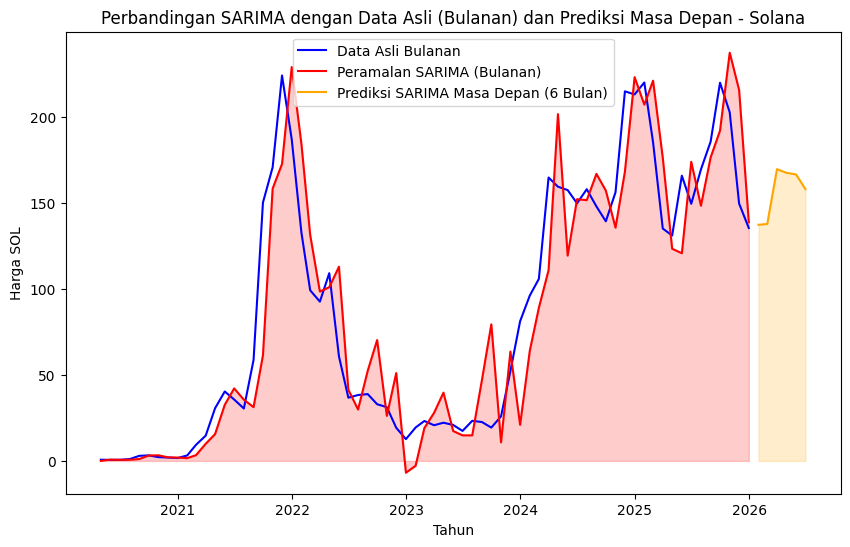

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(solana_monthly.index, solana_monthly['price'], label='Data Asli Bulanan', color='blue')  # Data asli Solana

# Menampilkan prediksi SARIMA dari awal hingga titik prediksi
plt.plot(solana_monthly.index, forecastsolana_monthly[:len(solana_monthly)], label='Peramalan SARIMA (Bulanan)', color='red')  # Peramalan SARIMA untuk Solana

# Menambahkan prediksi untuk masa depan (periode ke depan)
forecast_index = pd.date_range(start=solana_monthly.index[-1], periods=7, freq='ME')[1:]  # 6 periode prediksi untuk Solana
plt.plot(forecast_index, forecastsolana_monthly[-6:], label='Prediksi SARIMA Masa Depan (6 Bulan)', color='orange')

# Mengisi area prediksi SARIMA dengan bayangan
plt.fill_between(solana_monthly.index, forecastsolana_monthly[:len(solana_monthly)], color='red', alpha=0.2)
plt.fill_between(forecast_index, forecastsolana_monthly[-6:], color='orange', alpha=0.2)

# Menambahkan label dan judul
plt.legend()
plt.title('Perbandingan SARIMA dengan Data Asli (Bulanan) dan Prediksi Masa Depan - Solana')
plt.xlabel('Tahun')
plt.ylabel('Harga SOL')
plt.show()

In [ ]:
# Forecasting menggunakan SARIMA untuk data harian Solana
forecastsolana_daily, model_daily = sarima_forecast(solana_daily['price'], 12, 'D')

# Menyimpan nilai prediksi harian ke dalam variabel
sarsolana_harian = forecastsolana_daily[-12:]  # Menyimpan 12 nilai prediksi terakhir

# Menampilkan prediksi harian
print('Prediksi Harian:', sarsolana_harian)

# Evaluasi harian
maesolana_daily, rmsesolana_daily, mapesolana_daily = evaluate_forecast(solana_daily['price'][-12:], sarsolana_harian)
print(f'Harian MAE: {maesolana_daily}, RMSE: {rmsesolana_daily}, MAPE: {mapesolana_daily}%')

Prediksi Harian: 2025-12-11    138.427646
2025-12-12    138.324274
2025-12-13    141.173800
2025-12-14    142.468475
2025-12-15    140.727008
2025-12-16    139.420200
2025-12-17    138.614611
2025-12-18    139.159890
2025-12-19    139.433783
2025-12-20    140.296760
2025-12-21    141.326336
2025-12-22    138.064768
Freq: D, Name: predicted_mean, dtype: float64
Harian MAE: 5.290738320984229, RMSE: 6.829450091658506, MAPE: 3.987690791944274%


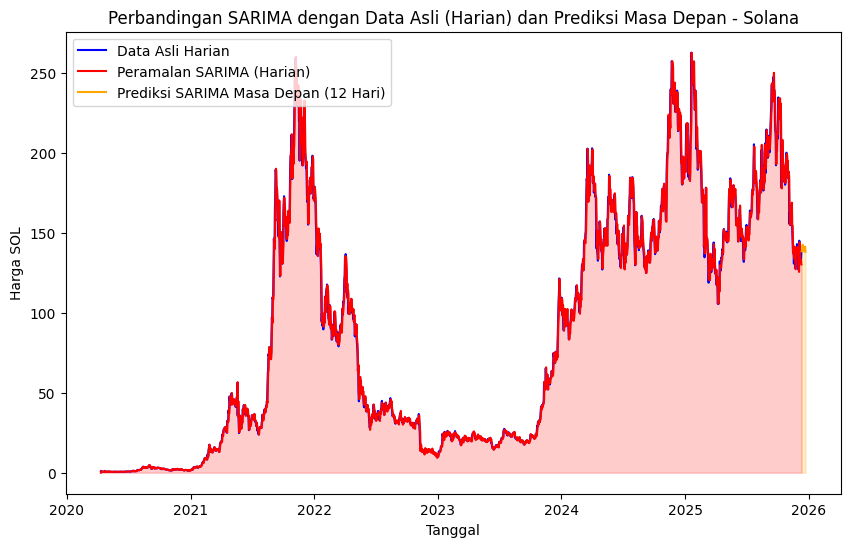

In [ ]:
# Grafik perbandingan antara data asli, SARIMA, dan prediksi masa depan
plt.figure(figsize=(10, 6))
plt.plot(solana_daily.index, solana_daily['price'], label='Data Asli Harian', color='blue')

# Menampilkan prediksi SARIMA dari awal hingga titik prediksi
plt.plot(solana_daily.index, forecastsolana_daily[:len(solana_daily)], label='Peramalan SARIMA (Harian)', color='red')

# Menambahkan prediksi untuk masa depan (periode ke depan)
forecast_index_daily = pd.date_range(start=solana_daily.index[-1], periods=13, freq='D')[1:]  # 12 periode prediksi
plt.plot(forecast_index_daily, forecastsolana_daily[-12:], label='Prediksi SARIMA Masa Depan (12 Hari)', color='orange')

# Mengisi area prediksi SARIMA dengan bayangan
plt.fill_between(solana_daily.index, forecastsolana_daily[:len(solana_daily)], color='red', alpha=0.2)
plt.fill_between(forecast_index_daily, forecastsolana_daily[-12:], color='orange', alpha=0.2)

# Menambahkan label dan judul
plt.legend()
plt.title('Perbandingan SARIMA dengan Data Asli (Harian) dan Prediksi Masa Depan - Solana')
plt.xlabel('Tanggal')
plt.ylabel('Harga SOL')
plt.show()

In [ ]:
# Forecasting menggunakan SARIMA untuk data tahunan Solana
forecastsolana_yearly, model_yearly = sarima_forecast(solana_yearly['price'], 3, 'A-DEC')

# Menampilkan prediksi tahunan
sarsolana_tahunan = forecastsolana_yearly[-3:]
print('Prediksi Tahunan:', sarsolana_tahunan)

# Evaluasi
maesolana_yearly, rmsesolana_yearly, mapesolana_yearly = evaluate_forecast(solana_yearly['price'][-3:], sarsolana_tahunan)
print(f'Tahunan MAE: {maesolana_yearly}, RMSE: {rmsesolana_yearly}, MAPE: {mapesolana_yearly}%')

Prediksi Tahunan: 2026-12-31    172.702822
2027-12-31    172.702822
2028-12-31    172.702822
Freq: YE-DEC, Name: predicted_mean, dtype: float64
Tahunan MAE: 53.71416373940622, RMSE: 83.54227174943686, MAPE: 168.48343628083057%


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning:

Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning:

Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.



/tmp/ipython-input-743369779.py:5: FutureWarning:

'A-DEC' is deprecated and will be removed in a future version, please use 'YE-DEC' instead.



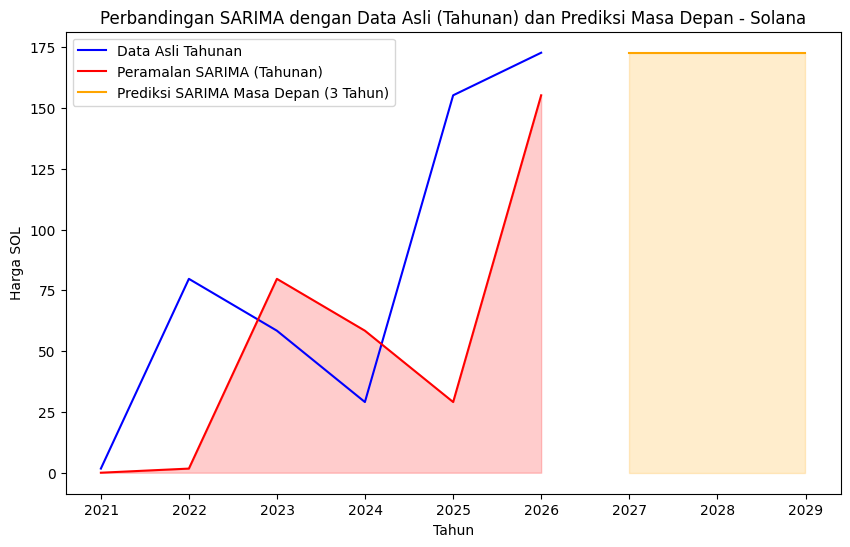

In [ ]:
# Grafik perbandingan antara data asli, SARIMA, dan prediksi masa depan
plt.figure(figsize=(10, 6))
plt.plot(solana_yearly.index, solana_yearly['price'], label='Data Asli Tahunan', color='blue')  # Data asli Solana
plt.plot(solana_yearly.index, forecastsolana_yearly[:len(solana_yearly)], label='Peramalan SARIMA (Tahunan)', color='red')  # Peramalan SARIMA
forecast_index_yearly = pd.date_range(start=solana_yearly.index[-1], periods=4, freq='A-DEC')[1:]
plt.plot(forecast_index_yearly, forecastsolana_yearly[-3:], label='Prediksi SARIMA Masa Depan (3 Tahun)', color='orange')
plt.fill_between(solana_yearly.index, forecastsolana_yearly[:len(solana_yearly)], color='red', alpha=0.2)
plt.fill_between(forecast_index_yearly, forecastsolana_yearly[-3:], color='orange', alpha=0.2)
plt.legend()
plt.title('Perbandingan SARIMA dengan Data Asli (Tahunan) dan Prediksi Masa Depan - Solana')
plt.xlabel('Tahun')
plt.ylabel('Harga SOL')
plt.show()

**HOLT-WINTERS**

In [ ]:
# Forecasting menggunakan Holt-Winters untuk data bulanan Solana
hotsolana_bulanan, model_monthly = holt_winters_forecast(solana_monthly['price'], 6, 12)

# Menyimpan nilai prediksi bulanan ke dalam variabel
hotsolana_bulanan = hotsolana_bulanan[-6:]  # Menyimpan 6 nilai prediksi terakhir

# Menampilkan prediksi bulanan
print('Prediksi Bulanan:', hotsolana_bulanan)

# Evaluasi bulanan (gunakan data yang sesuai untuk evaluasi)
mae_hotsolana_bulanan, rmse_hotsolana_bulanan, mape_hotsolana_bulanan = evaluate_forecast(solana_monthly['price'][-6:], hotsolana_bulanan)
print(f'Bulanan MAE: {mae_hotsolana_bulanan}, RMSE: {rmse_hotsolana_bulanan}, MAPE: {mape_hotsolana_bulanan}%')

Prediksi Bulanan: 2026-01-31    130.432482
2026-02-28    120.714709
2026-03-31    121.732037
2026-04-30    126.627186
2026-05-31    125.428177
2026-06-30    116.086836
Freq: ME, dtype: float64
Bulanan MAE: 53.396676014507314, RMSE: 60.50506111334166, MAPE: 28.34680338675959%


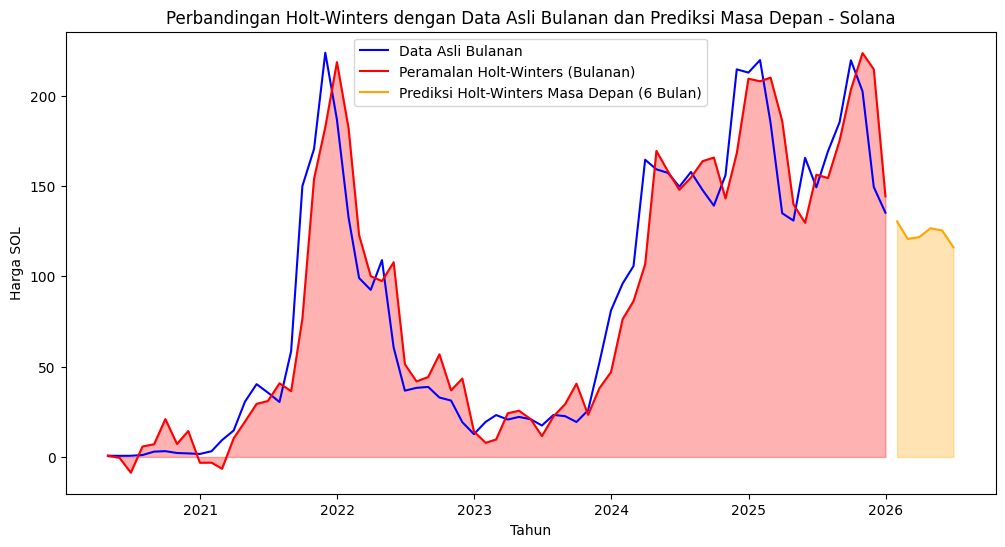

In [ ]:
# Grafik perbandingan antara data asli, Holt-Winters, dan prediksi masa depan
plt.figure(figsize=(12, 6))
plt.plot(solana_monthly.index, solana_monthly['price'], label='Data Asli Bulanan', color='blue')  # Data asli
plt.plot(solana_monthly.index, model_monthly.fittedvalues, label='Peramalan Holt-Winters (Bulanan)', color='red')  # Peramalan Holt-Winters
plt.plot(pd.date_range(solana_monthly.index[-1], periods=7, freq='ME')[1:], hotsolana_bulanan, label='Prediksi Holt-Winters Masa Depan (6 Bulan)', color='orange')  # Prediksi Masa Depan
plt.fill_between(pd.date_range(solana_monthly.index[-1], periods=7, freq='ME')[1:], hotsolana_bulanan, color='orange', alpha=0.3)  # Area bayangan untuk prediksi

# Menambahkan bayangan pada garis Holt-Winters
plt.fill_between(solana_monthly.index, model_monthly.fittedvalues, color='red', alpha=0.3)  # Area bayangan untuk Holt-Winters

# Menambahkan label dan judul
plt.title('Perbandingan Holt-Winters dengan Data Asli Bulanan dan Prediksi Masa Depan - Solana')
plt.xlabel('Tahun')
plt.ylabel('Harga SOL')
plt.legend()
plt.show()

In [ ]:
# Menghapus nilai NaN jika ada
solana_daily_cleaned = solana_daily.dropna()

# Forecasting menggunakan Holt-Winters untuk data harian dengan prediksi 12 hari ke depan
hotsolana_harian1, model_daily = holt_winters_forecast(solana_daily_cleaned['price'], 12, 7)  # 12 untuk prediksi 12 hari, 7 untuk musiman mingguan

# Menyimpan nilai prediksi harian ke dalam variabel
hotsolana_harian = hotsolana_harian1  # Menyimpan semua prediksi untuk penggunaan lebih lanjut

# Menampilkan nilai prediksi harian
print('Prediksi Harian:', hotsolana_harian)

# Evaluasi model harian (gunakan data yang sesuai untuk evaluasi)
mae_hotsolana_harian, rmse_hotsolana_harian, mape_hotsolana_harian = evaluate_forecast(solana_daily['price'][-6:], hotsolana_harian[:6])
print(f'Harian MAE: {mae_hotsolana_harian}, RMSE: {rmse_hotsolana_harian}, MAPE: {mape_hotsolana_harian}%')

Prediksi Harian: 2025-12-11    138.682887
2025-12-12    138.647587
2025-12-13    138.496162
2025-12-14    138.918255
2025-12-15    139.223539
2025-12-16    138.774653
2025-12-17    138.478837
2025-12-18    139.149035
2025-12-19    139.113735
2025-12-20    138.962309
2025-12-21    139.384402
2025-12-22    139.689686
Freq: D, dtype: float64
Harian MAE: 4.3385162500220575, RMSE: 5.133155687727205, MAPE: 3.2683457862845855%


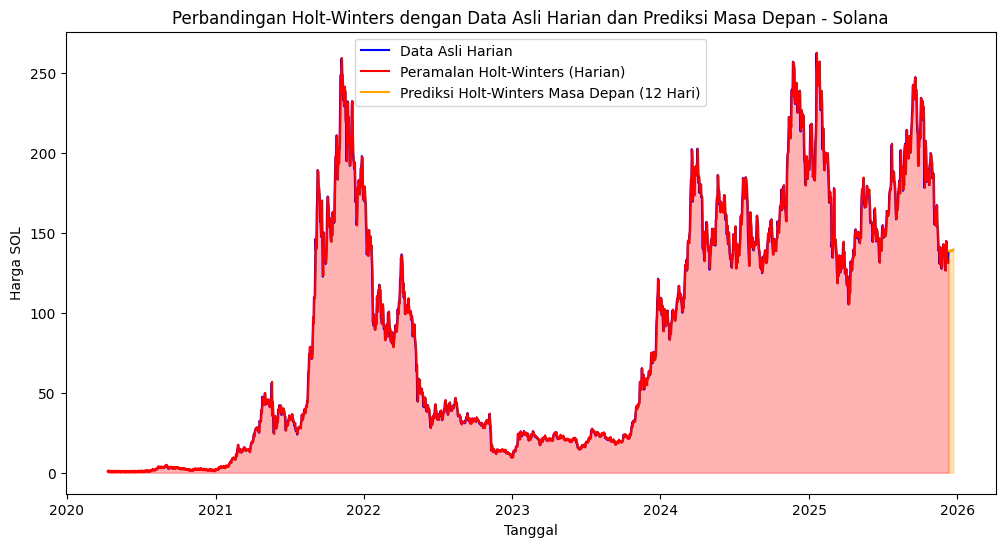

In [ ]:
# Grafik perbandingan antara data asli, Holt-Winters, dan prediksi masa depan
plt.figure(figsize=(12, 6))

# Plot data asli Solana
plt.plot(solana_daily.index, solana_daily['price'], label='Data Asli Harian', color='blue')

# Menampilkan peramalan Holt-Winters (hanya untuk data historis)
plt.plot(solana_daily.index[:len(model_daily.fittedvalues)], model_daily.fittedvalues, label='Peramalan Holt-Winters (Harian)', color='red')
forecast_index_daily = pd.date_range(start=solana_daily.index[-1], periods=13, freq='D')[1:]  # 12 periode prediksi
plt.plot(forecast_index_daily, hotsolana_harian_predictions, label='Prediksi Holt-Winters Masa Depan (12 Hari)', color='orange')
plt.fill_between(solana_daily.index[:len(model_daily.fittedvalues)], model_daily.fittedvalues, color='red', alpha=0.3)
plt.fill_between(forecast_index_daily, hotsolana_harian_predictions, color='orange', alpha=0.3)

# Menambahkan label dan judul
plt.title('Perbandingan Holt-Winters dengan Data Asli Harian dan Prediksi Masa Depan - Solana')
plt.xlabel('Tanggal')
plt.ylabel('Harga SOL')
plt.legend()
plt.show()

In [ ]:
# Forecasting menggunakan Holt-Winters untuk data tahunan Solana
hotsolana_yearly, model_yearly = holt_winters_forecast(solana_yearly['price'], 3, 1)  # 3 untuk prediksi 3 tahun, 1 untuk musiman tahunan

# Menyimpan nilai prediksi tahunan ke dalam variabel
hotsolana_tahunan = hotsolana_yearly  # Menyimpan semua prediksi untuk penggunaan lebih lanjut

# Menampilkan nilai prediksi tahunan
print('Prediksi Tahunan:', hotsolana_tahunan)

# Evaluasi model tahunan (gunakan data yang sesuai untuk evaluasi)
mae_hotsolana_yearly, rmse_hotsolana_yearly, mape_hotsolana_yearly = evaluate_forecast(solana_yearly['price'][-3:], hotsolana_tahunan)
print(f'Tahunan MAE: {mae_hotsolana_yearly}, RMSE: {rmse_hotsolana_yearly}, MAPE: {mape_hotsolana_yearly}%')

Prediksi Tahunan: 2026-12-31    188.008975
2027-12-31    218.069496
2028-12-31    248.130018
Freq: YE-DEC, dtype: float64
Tahunan MAE: 99.08083778066629, RMSE: 107.86569315827401, MAPE: 210.33872202306605%


/tmp/ipython-input-3549238142.py:5: FutureWarning:

'A-DEC' is deprecated and will be removed in a future version, please use 'YE-DEC' instead.

/tmp/ipython-input-3549238142.py:6: FutureWarning:

'A-DEC' is deprecated and will be removed in a future version, please use 'YE-DEC' instead.



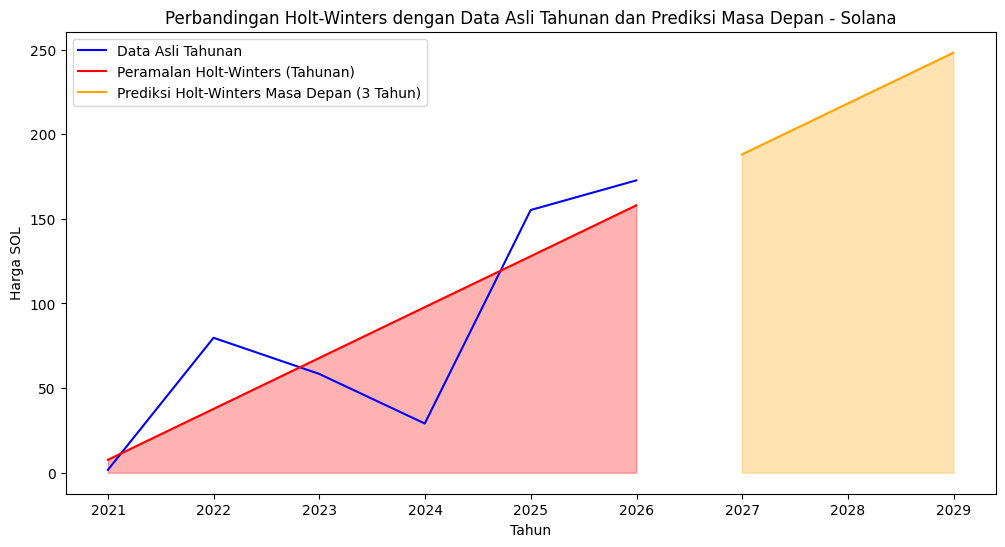

In [ ]:
# Grafik perbandingan antara data asli, Holt-Winters, dan prediksi masa depan
plt.figure(figsize=(12, 6))
plt.plot(solana_yearly.index, solana_yearly['price'], label='Data Asli Tahunan', color='blue')  # Data asli Solana
plt.plot(solana_yearly.index, model_yearly.fittedvalues, label='Peramalan Holt-Winters (Tahunan)', color='red')  # Peramalan Holt-Winters
plt.plot(pd.date_range(solana_yearly.index[-1], periods=4, freq='A-DEC')[1:], hotsolana_yearly_predictions, label='Prediksi Holt-Winters Masa Depan (3 Tahun)', color='orange')  # Prediksi Masa Depan
plt.fill_between(pd.date_range(solana_yearly.index[-1], periods=4, freq='A-DEC')[1:], hotsolana_yearly_predictions, color='orange', alpha=0.3)  # Area bayangan untuk prediksi

# Menambahkan bayangan pada garis Holt-Winters
plt.fill_between(solana_yearly.index, model_yearly.fittedvalues, color='red', alpha=0.3)  # Area bayangan untuk Holt-Winters

# Menambahkan label dan judul
plt.title('Perbandingan Holt-Winters dengan Data Asli Tahunan dan Prediksi Masa Depan - Solana')
plt.xlabel('Tahun')
plt.ylabel('Harga SOL')
plt.legend()
plt.show()

# Evaluasi Hasil Forecasting Bulanan

/tmp/ipython-input-3059111725.py:12: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



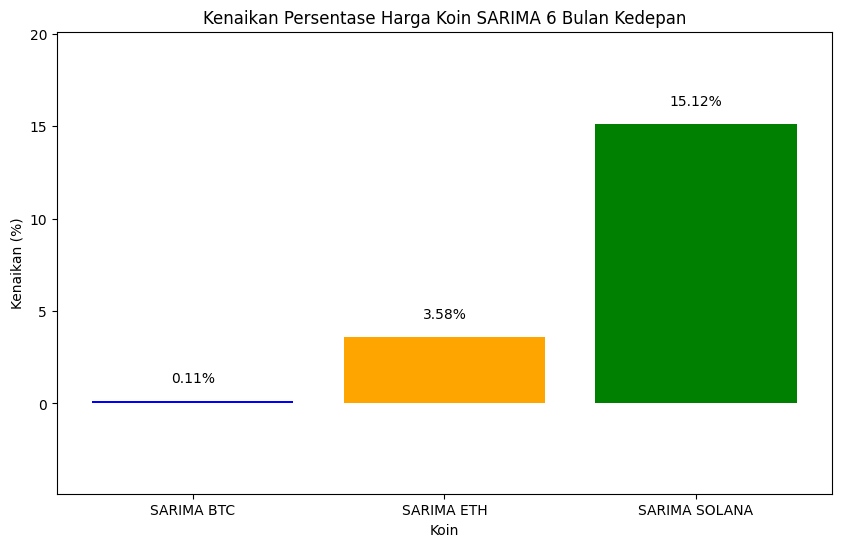

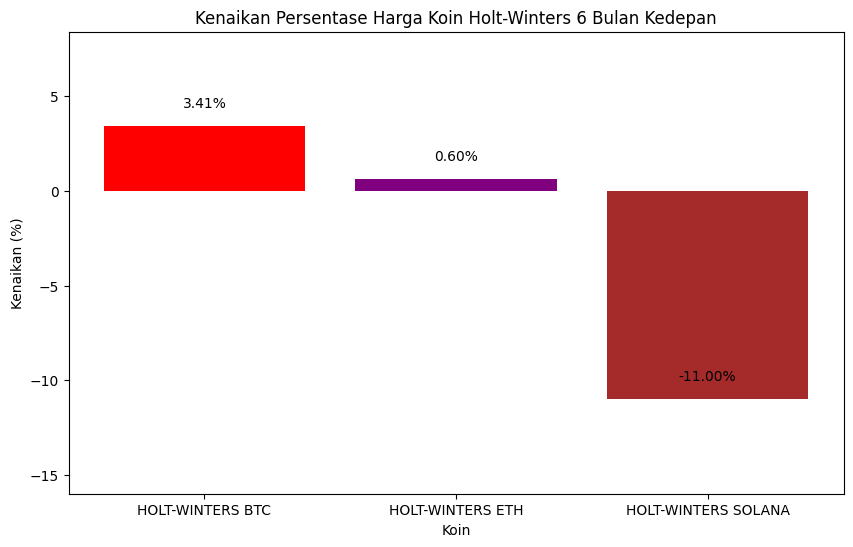

In [ ]:
# Ambil data 6 bulan terakhir
forecast_months_sarbtc = sarbtc_bulanan[-6:]
forecast_months_sareth = sareth_bulanan[-6:]
forecast_months_sarsolana = sarsolana_bulanan[-6:]

forecast_months_hotbtc = hotbtc_bulanan[-6:]
forecast_months_hoteth = hoteth_bulanan[-6:]
forecast_months_hotsolana = hotsolana_bulanan[-6:]

# Fungsi untuk menghitung persentase kenaikan
def hitung_persen_kenaikan(data):
    return ((data[-1] - data[0]) / data[0]) * 100

# Hitung persentase kenaikan untuk masing-masing koin
kenaikan_sarbtc = hitung_persen_kenaikan(forecast_months_sarbtc)
kenaikan_sareth = hitung_persen_kenaikan(forecast_months_sareth)
kenaikan_sarsolana = hitung_persen_kenaikan(forecast_months_sarsolana)

kenaikan_hotbtc = hitung_persen_kenaikan(forecast_months_hotbtc)
kenaikan_hoteth = hitung_persen_kenaikan(forecast_months_hoteth)
kenaikan_hotsolana = hitung_persen_kenaikan(forecast_months_hotsolana)

# Data persentase kenaikan untuk masing-masing grup
data_kenaikan_sarima = [kenaikan_sarbtc, kenaikan_sareth, kenaikan_sarsolana]
data_kenaikan_holtwinters = [kenaikan_hotbtc, kenaikan_hoteth, kenaikan_hotsolana]

# Nama koin untuk label
koin_sarima = ["SARIMA BTC", "SARIMA ETH", "SARIMA SOLANA"]
koin_holtwinters = ["HOLT-WINTERS BTC", "HOLT-WINTERS ETH", "HOLT-WINTERS SOLANA"]

# Plot Diagram Balok SARIMA
plt.figure(figsize=(10, 6))
plt.bar(koin_sarima, data_kenaikan_sarima, color=['blue', 'orange', 'green'])
plt.title('Kenaikan Persentase Harga Koin SARIMA 6 Bulan Kedepan')
plt.xlabel('Koin')
plt.ylabel('Kenaikan (%)')
plt.ylim(min(data_kenaikan_sarima) - 5, max(data_kenaikan_sarima) + 5)

# Menambahkan nilai persentase pada setiap bar
for i, v in enumerate(data_kenaikan_sarima):
    plt.text(i, v + 1, f"{v:.2f}%", ha='center')

plt.show()

# Plot Diagram Balok Holt-Winters
plt.figure(figsize=(10, 6))
plt.bar(koin_holtwinters, data_kenaikan_holtwinters, color=['red', 'purple', 'brown'])
plt.title('Kenaikan Persentase Harga Koin Holt-Winters 6 Bulan Kedepan')
plt.xlabel('Koin')
plt.ylabel('Kenaikan (%)')
plt.ylim(min(data_kenaikan_holtwinters) - 5, max(data_kenaikan_holtwinters) + 5)

# Menambahkan nilai persentase pada setiap bar
for i, v in enumerate(data_kenaikan_holtwinters):
    plt.text(i, v + 1, f"{v:.2f}%", ha='center')

plt.show()

# Evaluasi Hasil Forecasting Harian

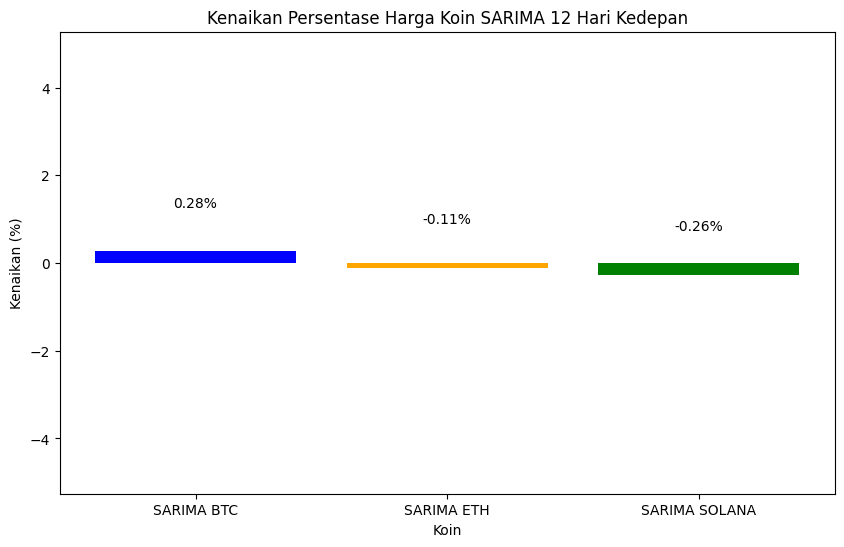

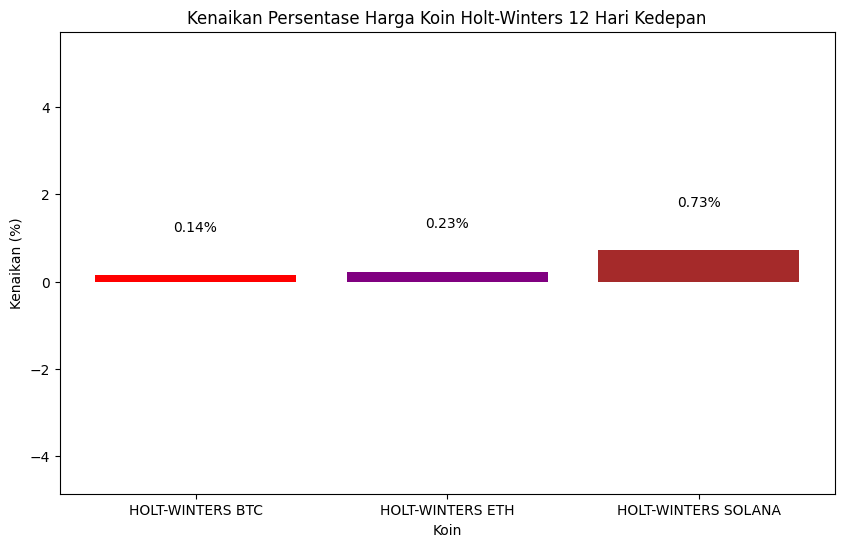

In [ ]:
forecast_days_sarbtc = sarbtc_harian[-12:]  # 3 bulan terakhir (asumsi 30 hari per bulan)
forecast_days_sareth = sareth_harian[-12:]
forecast_days_sarsolana = sarsolana_harian[-12:]

forecast_days_hotbtc = hotbtc_harian[-12:]
forecast_days_hoteth = hoteth_harian[-12:]
forecast_days_hotsolana = hotsolana_harian[-12:]

def hitung_persen_kenaikan(data):
    return ((data.iloc[-1] - data.iloc[0]) / data.iloc[0]) * 100

# Hitung persentase kenaikan untuk masing-masing koin
kenaikan_sarbtc = hitung_persen_kenaikan(forecast_days_sarbtc)
kenaikan_sareth = hitung_persen_kenaikan(forecast_days_sareth)
kenaikan_sarsolana = hitung_persen_kenaikan(forecast_days_sarsolana)

kenaikan_hotbtc = hitung_persen_kenaikan(forecast_days_hotbtc)
kenaikan_hoteth = hitung_persen_kenaikan(forecast_days_hoteth)
kenaikan_hotsolana = hitung_persen_kenaikan(forecast_days_hotsolana)

# Data persentase kenaikan untuk masing-masing grup
data_kenaikan_sarima = [kenaikan_sarbtc, kenaikan_sareth, kenaikan_sarsolana]
data_kenaikan_holtwinters = [kenaikan_hotbtc, kenaikan_hoteth, kenaikan_hotsolana]

# Nama koin untuk label
koin_sarima = ["SARIMA BTC", "SARIMA ETH", "SARIMA SOLANA"]
koin_holtwinters = ["HOLT-WINTERS BTC", "HOLT-WINTERS ETH", "HOLT-WINTERS SOLANA"]

# Plot Diagram Balok SARIMA
plt.figure(figsize=(10, 6))
plt.bar(koin_sarima, data_kenaikan_sarima, color=['blue', 'orange', 'green'])
plt.title('Kenaikan Persentase Harga Koin SARIMA 12 Hari Kedepan')
plt.xlabel('Koin')
plt.ylabel('Kenaikan (%)')
plt.ylim(min(data_kenaikan_sarima) - 5, max(data_kenaikan_sarima) + 5)

# Menambahkan nilai persentase pada setiap bar
for i, v in enumerate(data_kenaikan_sarima):
    plt.text(i, v + 1, f"{v:.2f}%", ha='center')

plt.show()

# Plot Diagram Balok Holt-Winters
plt.figure(figsize=(10, 6))
plt.bar(koin_holtwinters, data_kenaikan_holtwinters, color=['red', 'purple', 'brown'])
plt.title('Kenaikan Persentase Harga Koin Holt-Winters 12 Hari Kedepan')
plt.xlabel('Koin')
plt.ylabel('Kenaikan (%)')
plt.ylim(min(data_kenaikan_holtwinters) - 5, max(data_kenaikan_holtwinters) + 5)

# Menambahkan nilai persentase pada setiap bar
for i, v in enumerate(data_kenaikan_holtwinters):
    plt.text(i, v + 1, f"{v:.2f}%", ha='center')

plt.show()

# Evaluasi Hasil Forecasting Tahunan

/tmp/ipython-input-3979578298.py:12: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



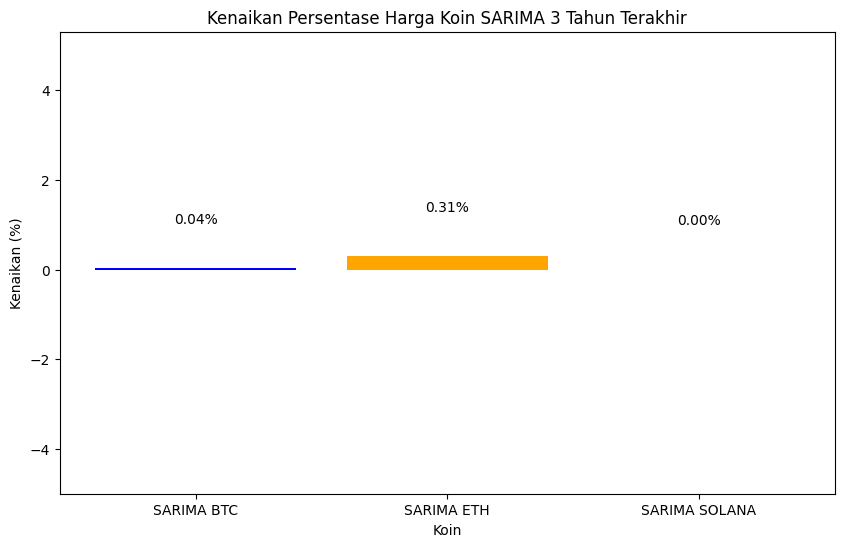

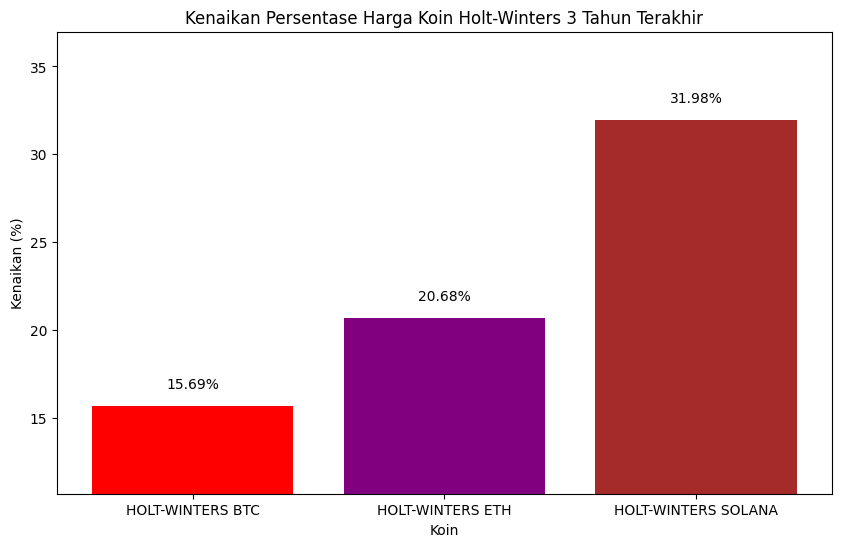

In [ ]:
# Ambil data 3 tahun terakhir
forecast_years_sarbtc = sarbtc_tahunan[-3:]
forecast_years_sareth = sareth_tahunan[-3:]
forecast_years_sarsolana = sarsolana_tahunan[-3:]

forecast_years_hotbtc = hotbtc_tahunan[-3:]
forecast_years_hoteth = hoteth_tahunan[-3:]
forecast_years_hotsolana = hotsolana_tahunan[-3:]

# Fungsi untuk menghitung persentase kenaikan
def hitung_persen_kenaikan(data):
    return ((data[-1] - data[0]) / data[0]) * 100

# Hitung persentase kenaikan untuk masing-masing koin
kenaikan_sarbtc = hitung_persen_kenaikan(forecast_years_sarbtc)
kenaikan_sareth = hitung_persen_kenaikan(forecast_years_sareth)
kenaikan_sarsolana = hitung_persen_kenaikan(forecast_years_sarsolana)

kenaikan_hotbtc = hitung_persen_kenaikan(forecast_years_hotbtc)
kenaikan_hoteth = hitung_persen_kenaikan(forecast_years_hoteth)
kenaikan_hotsolana = hitung_persen_kenaikan(forecast_years_hotsolana)

# Data persentase kenaikan untuk masing-masing grup
data_kenaikan_sarima = [kenaikan_sarbtc, kenaikan_sareth, kenaikan_sarsolana]
data_kenaikan_holtwinters = [kenaikan_hotbtc, kenaikan_hoteth, kenaikan_hotsolana]

# Nama koin untuk label
koin_sarima = ["SARIMA BTC", "SARIMA ETH", "SARIMA SOLANA"]
koin_holtwinters = ["HOLT-WINTERS BTC", "HOLT-WINTERS ETH", "HOLT-WINTERS SOLANA"]

# Plot Diagram Balok SARIMA
plt.figure(figsize=(10, 6))
plt.bar(koin_sarima, data_kenaikan_sarima, color=['blue', 'orange', 'green'])
plt.title('Kenaikan Persentase Harga Koin SARIMA 3 Tahun Kedepan')
plt.xlabel('Koin')
plt.ylabel('Kenaikan (%)')
plt.ylim(min(data_kenaikan_sarima) - 5, max(data_kenaikan_sarima) + 5)

# Menambahkan nilai persentase pada setiap bar
for i, v in enumerate(data_kenaikan_sarima):
    plt.text(i, v + 1, f"{v:.2f}%", ha='center')

plt.show()

# Plot Diagram Balok Holt-Winters
plt.figure(figsize=(10, 6))
plt.bar(koin_holtwinters, data_kenaikan_holtwinters, color=['red', 'purple', 'brown'])
plt.title('Kenaikan Persentase Harga Koin Holt-Winters 3 Tahun Kedepan')
plt.xlabel('Koin')
plt.ylabel('Kenaikan (%)')
plt.ylim(min(data_kenaikan_holtwinters) - 5, max(data_kenaikan_holtwinters) + 5)

# Menambahkan nilai persentase pada setiap bar
for i, v in enumerate(data_kenaikan_holtwinters):
    plt.text(i, v + 1, f"{v:.2f}%", ha='center')

plt.show()

# Kesimpulan

1. Peramalan 6 Bulan Kedepan
Dalam peramalan jangka 6 bulan, kita melihat perbedaan hasil yang cukup signifikan antara dua metode yang digunakan.

Jika kita menggunakan metode SARIMA, Solana (SOL) diperkirakan akan mengalami kenaikan harga yang paling besar, yaitu sekitar 15,12%. Ini menunjukkan bahwa dalam 6 bulan ke depan, Solana berpotensi memberikan keuntungan yang cukup besar dibandingkan dengan dua koin lainnya. Ethereum (ETH) juga diperkirakan akan mengalami kenaikan harga, namun lebih kecil, yaitu sekitar 3,58%. Sementara itu, Bitcoin (BTC) diperkirakan hanya mengalami kenaikan yang sangat kecil, yaitu 0,11%, yang hampir tidak memberikan perubahan yang signifikan dalam periode tersebut.

Namun, jika kita beralih menggunakan metode Holt-Winters, hasilnya jauh berbeda. Pada metode ini, Bitcoin (BTC) diperkirakan akan mengalami kenaikan yang lebih baik, sekitar 3,41%. Ini menunjukkan bahwa dalam 6 bulan ke depan, Bitcoin akan lebih stabil dengan kenaikan yang cukup baik. Ethereum (ETH) hanya diperkirakan mengalami kenaikan yang sangat kecil, sekitar 0,60%, sementara Solana (SOL) justru diperkirakan akan mengalami penurunan yang cukup signifikan, yaitu -11,00%. Hal ini menunjukkan bahwa meskipun Solana memiliki potensi pertumbuhan yang baik menurut SARIMA, Holt-Winters memprediksi adanya penurunan harga dalam periode yang sama.

2. Peramalan 12 Hari Kedepan

Berlanjut ke peramalan untuk periode yang lebih singkat, yaitu 12 hari. Dalam periode ini, kedua metode memberikan hasil yang relatif serupa, meskipun tidak ada perubahan harga yang signifikan.

Menggunakan metode SARIMA, Bitcoin (BTC) diperkirakan akan mengalami kenaikan kecil, yaitu sekitar 0,28%. Ethereum (ETH) dan Solana (SOL) justru diperkirakan akan sedikit mengalami penurunan, yaitu masing-masing -0,11% untuk Ethereum dan -0,26% untuk Solana. Hasil ini menunjukkan bahwa dalam periode yang sangat pendek, Bitcoin sedikit lebih baik dengan kenaikan yang positif, meskipun tetap kecil.

Namun, jika kita menggunakan metode Holt-Winters untuk melihat hasil peramalan 12 hari, kita mendapatkan gambaran yang sedikit berbeda. Di sini, Solana (SOL) diperkirakan akan mengalami kenaikan harga yang lebih besar, yaitu sekitar 0,73%, sementara Ethereum (ETH) dan Bitcoin (BTC) diperkirakan mengalami kenaikan yang lebih kecil, masing-masing 0,23% dan 0,14%. Dalam jangka waktu yang sangat pendek, Solana menunjukkan potensi kenaikan yang sedikit lebih baik dibandingkan dengan Bitcoin dan Ethereum.

3. Peramalan 3 Tahun Kedepan

Akhirnya, untuk peramalan jangka panjang, yaitu dalam 3 tahun ke depan, perbedaan antara kedua metode semakin jelas.

Menggunakan metode SARIMA, kita melihat bahwa Ethereum (ETH) diperkirakan akan mengalami kenaikan harga sekitar 0,31%, sementara Bitcoin (BTC) hanya diperkirakan naik sedikit, yaitu 0,04%. Solana (SOL) diperkirakan tidak akan mengalami perubahan harga sama sekali (0%). Ini menunjukkan bahwa dalam jangka waktu yang panjang, baik Bitcoin maupun Solana cenderung tidak mengalami pertumbuhan yang signifikan menurut metode SARIMA, dan hanya Ethereum yang diperkirakan akan sedikit naik.

Namun, dengan metode Holt-Winters, prediksi jangka panjang memberikan gambaran yang lebih optimis. Solana (SOL) diperkirakan akan mengalami kenaikan harga yang terbesar, yaitu 31,98%, menunjukkan potensi pertumbuhan yang sangat besar dalam 3 tahun ke depan. Ethereum (ETH) juga diperkirakan akan mengalami kenaikan yang baik, yaitu 20,68%, sedangkan Bitcoin (BTC) diperkirakan akan naik lebih sedikit, sekitar 15,69%. Ini menunjukkan bahwa dalam jangka panjang, Solana bisa memberikan keuntungan yang lebih besar dibandingkan dengan Ethereum dan Bitcoin.